# HW1 — Statistical inference and supervised learning

**EE-411 — Fundamentals of Inference and Learning, 2026–2027**

**Learning objectives**
- Derive and compare estimators, quantify uncertainty, and interpret their limits.
- Fit and compare classifiers using cross-validation and a final test set.
- Diagnose class imbalance and apply resampling without leaking validation data.

**Prerequisites:** probability densities, likelihood, basic Bayesian inference, Fisher
information, classification, and Python/NumPy. Required packages are listed in
`requirements.txt`. Open this notebook with `HW1/` as the working directory.

**Working period:** approximately three weeks. The two parts are independent;
plan time for both mathematical reasoning and numerical experiments.

Submit your completed exercise notebook on Moodle by the announced deadline.
Each student submits their own work. AI tools may be used, but you are responsible
for checking and explaining every result. Briefly document how you used them.
Questions marked **optional** are extensions; the remaining questions form the core.

Put mathematical and written answers in the answer slots (you may use
`display(Markdown(r"..."))`), together with the requested code. Explain results;
tables or scores without interpretation are not complete answers. Run your
notebook from a fresh kernel before submitting it.

Use the supplied data; you do not need to download images or run the generators.
We use a fixed random seed (`SEED`) so that random operations give reproducible
results across runs. Setting `random_state=SEED` uses this fixed seed. A seed fixes
one realization, not a universal estimator or classifier ranking.

In [1]:
# PROVIDED: common imports and reproducibility settings.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 2203
plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True})

## Part I — Statistical inference and estimation

Alex encodes the first two and last two digits of a phone code as parameters
$a$ and $b$. For $0<a<b$, consider the triangular density

$$p(x;a,b)=H(a,b)\begin{cases}
x/a,&0\leq x\leq a,\\
(b-x)/(b-a),&a<x\leq b,\\
0,&\text{otherwise}.
\end{cases}$$

We first treat the parameters as continuous. At the end, discuss the additional
constraint that a code consists of integer pairs. The files in this part reproduce
the current 2026 HW1 data. Do not inspect `generator.py` to obtain the answers.

### Question 1 — Normalization and expectation

Find $H(a,b)$ and derive the mean $\mu=\mathbb E[X]$. Show the integrals.

In [2]:
# TODO: answer Question 1, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

display(Markdown(r"""We have that the integral of the probability density $p(x;a,b)$ must be 1. \\
    Thus we have:
    $$ \begin{aligned} 
    \int_{-\infty}^{\infty} p(x;a,b) dx 
    &= \int_{-\infty}^{\infty} H(a,b)\begin{cases} x/a,&0\leq x\leq a\\ (b-x)/(b-a),&a<x\leq b\\
    0&\text{otherwise} \end{cases} \ dx \\
    &= H(a,b) \biggr[ \int_{0}^{a}\frac{x}{a}  dx + \int_{a}^{b}\frac{b-x}{b-a}  dx \biggr]\\
    &= H(a,b) \biggr[\frac{x^2}{2a}\biggr\rvert_{0}^{a} + \frac{bx-\frac{1}{2}x^2}{b-a}\biggr\rvert_{a}^b\biggr]\\
    &= H(a,b) \biggr[\frac{a}{2}+ \frac{\frac{1}{2} (b-a)^2}{b-a}\biggr]\\
    &= H(a,b) \frac{b}{2}\\
    &= 1\\
    \Leftrightarrow H(a,b) = \frac{2}{b}
    \end{aligned}$$
    For the mean, we have:
    $$\begin{aligned}
    \mu = \mathbb E[X]
    &=\int_{-\infty}^{\infty}x \cdot p(x;a,b) dx\\
    &= \frac{2}{b} \biggr[ \int_0^a \frac{x^2}{a} dx + \int_a^b \frac{bx-x^2} {b-a}  dx \biggr]\\
    &= \frac{2}{b} \biggr[ \frac{x^3}{3a} \biggr\rvert_0^a + \frac{\frac{b}{2}x^2 - \frac{1}{3}x^3}{b-a}\biggr\rvert_a^b \biggr] \\
    &= \frac{2}{b} \biggr[  \frac{a^2}{3} b+ \frac{\frac{1}{6}b^3 - \frac{1}{2}a^2b + \frac{1}{3}a^3}{b-a} \biggr]\\
    &= \frac{2}{b} \biggr[\frac{1}{6} \frac{b\cdot(b^2-a^2)}{b-a}    \biggr]\\ 
    &=\frac{1}{3} \frac{(b-a)(b+a)}{b-a} = \frac{b+a}{3} 
    \end{aligned}$$
   """))

We have that the integral of the probability density $p(x;a,b)$ must be 1. \\
    Thus we have:
    $$ \begin{aligned} 
    \int_{-\infty}^{\infty} p(x;a,b) dx 
    &= \int_{-\infty}^{\infty} H(a,b)\begin{cases} x/a,&0\leq x\leq a\\ (b-x)/(b-a),&a<x\leq b\\
    0&\text{otherwise} \end{cases} \ dx \\
    &= H(a,b) \biggr[ \int_{0}^{a}\frac{x}{a}  dx + \int_{a}^{b}\frac{b-x}{b-a}  dx \biggr]\\
    &= H(a,b) \biggr[\frac{x^2}{2a}\biggr\rvert_{0}^{a} + \frac{bx-\frac{1}{2}x^2}{b-a}\biggr\rvert_{a}^b\biggr]\\
    &= H(a,b) \biggr[\frac{a}{2}+ \frac{\frac{1}{2} (b-a)^2}{b-a}\biggr]\\
    &= H(a,b) \frac{b}{2}\\
    &= 1\\
    \Leftrightarrow H(a,b) = \frac{2}{b}
    \end{aligned}$$
    For the mean, we have:
    $$\begin{aligned}
    \mu = \mathbb E[X]
    &=\int_{-\infty}^{\infty}x \cdot p(x;a,b) dx\\
    &= \frac{2}{b} \biggr[ \int_0^a \frac{x^2}{a} dx + \int_a^b \frac{bx-x^2} {b-a}  dx \biggr]\\
    &= \frac{2}{b} \biggr[ \frac{x^3}{3a} \biggr\rvert_0^a + \frac{\frac{b}{2}x^2 - \frac{1}{3}x^3}{b-a}\biggr\rvert_a^b \biggr] \\
    &= \frac{2}{b} \biggr[  \frac{a^2}{3} b+ \frac{\frac{1}{6}b^3 - \frac{1}{2}a^2b + \frac{1}{3}a^3}{b-a} \biggr]\\
    &= \frac{2}{b} \biggr[\frac{1}{6} \frac{b\cdot(b^2-a^2)}{b-a}    \biggr]\\ 
    &=\frac{1}{3} \frac{(b-a)(b+a)}{b-a} = \frac{b+a}{3} 
    \end{aligned}$$
   

### Question 2 — CDF, median, and mode

Derive the cumulative distribution function $F(t)=\Pr(X\leq t)$ and the median
$m$. Distinguish the cases $a\leq b/2$ and $a>b/2$. Compare the mean, median,
and mode, including the symmetric case.

In [3]:
# TODO: answer Question 2, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
display(Markdown(r"""Let's first compute the cumulative distribution function
$$ \begin{aligned}
F(t) = Pr(X\leq t)\\
&= \int_{-\infty}^t p(x;a,b) dx\\
&= \begin{cases} 0, & t < 0\\  \frac{2}{b} \int_0^t \frac{x}{a} dx & 0\leq t\leq a\\ \frac{2}{b} \int_0^a \frac{x}{a} dx +\frac{2}{b} \int_a^t \frac{b-x}{b-a} dx&a<x\leq b\\1& t>b \end{cases}\\
&= \begin{cases} 0, & t < 0\\  \frac{2}{b} \frac{x^2}{2a}\biggr\rvert_0^t  & 0\leq t\leq a\\ \frac{2}{b} \frac{x^2}{2a}\biggr\rvert_0^t + \frac{2}{b} \frac{bx-\frac{1}{2}t^2}{b-a} \biggr\rvert_a^t &a<x\leq b\\1& t>b \end{cases}\\
&= \begin{cases} 0, & t < 0\\  \frac{t^2}{ab} & 0\leq t\leq a\\ 1-\frac{(b-t)^2}{b(b-a)}&a<x\leq b\\1& t>b \end{cases}\\
\end{aligned}$$
For the median m we have that $F(m) = Pr(X\leq m) = \frac{1}{2}$.
Let's evaluate $F$ at a so that we can determine if the median is in the interval $[0,a]$ or in $(a,b]$.
- Case 1: $a>\frac{b}{2} \quad \Rightarrow F(a)=\frac{a}{b} > \frac{1}{2}$. Thus $m\in [0,a]$ and $F(m)=\frac{m^2}{ab}=\frac{1}{2} \Leftrightarrow m = \sqrt{\frac{ab}{2}}$
- Case 2: $a\leq\frac{b}{2} \quad \Rightarrow F(a)=\frac{a}{b} \leq\frac{1}{2}$. Thus $m\in (a,b]$ and $F(m)=1-\frac{(b-m)^2}{b(b-a)}=\frac{1}{2} \Leftrightarrow m= b\pm \sqrt{\frac{b(b-a)}{2}}$. But because $a< m \leq b$, we find that $m= b- \sqrt{\frac{b(b-a)}{2}}$.
For the comparison, let's recall that we have the mean $\mu = \frac{a+b}{3}$. The mode is found as follows: it is the value of $x$ where the probability density $p(x;a,b)$ is the largest.\\
Recall the probability density function:
$$
p(x;a,b)=\frac{2}{b}
\begin{cases}
\dfrac{x}{a}&0\le x\le a\\
\dfrac{b-x}{b-a},&a<x\le b\\
0&\text{otherwise}.
\end{cases}
$$
When $0\le x\le a$ the pdf is $\frac{x}{a}$, which is increasing in $x$. Hence, the density increases as $x$ approaches $a$.
When $a<x\le b$ the pdf is $\frac{b-x}{b-a}$, which is decreasing in $x$. Hence, the density decreases after $a$. We deduce that the density is largest at $x=a$ and $\text{mode}=a$.
Let's compare the mean, the median and the mode for 3 cases:
- Case 1: $a>\frac{b}{2}$. Here we have that the mode $a$ is larger than the midpoint and hence, the distribution is left-skewed and we have that the mode is larger than the median which is in turn larger than the mean: $$a > \sqrt{\frac{ab}{2}} >\frac{a+b}{3} $$
- Case 2: $a < \frac{b}{2}$. Here we have that the mode $a$ is smaller than the midpoint and hence, the distribution is right-skewed and we have that the mode is smaller than the median which is in turn smaller than the mean: $$a < b-\sqrt{\frac{b(b-a)}{2}} < \frac{a+b}{3} $$
- Case 3: $a=\frac{b}{2}$. Here we have that the mode $a$ is exactly at the midpoint and hence, the distribution is perfectly symmetric and we have than the mode, the median and the mean are equal to $\frac{b}{2}$."""))

Let's first compute the cumulative distribution function
$$ \begin{aligned}
F(t) = Pr(X\leq t)\\
&= \int_{-\infty}^t p(x;a,b) dx\\
&= \begin{cases} 0, & t < 0\\  \frac{2}{b} \int_0^t \frac{x}{a} dx & 0\leq t\leq a\\ \frac{2}{b} \int_0^a \frac{x}{a} dx +\frac{2}{b} \int_a^t \frac{b-x}{b-a} dx&a<x\leq b\\1& t>b \end{cases}\\
&= \begin{cases} 0, & t < 0\\  \frac{2}{b} \frac{x^2}{2a}\biggr\rvert_0^t  & 0\leq t\leq a\\ \frac{2}{b} \frac{x^2}{2a}\biggr\rvert_0^t + \frac{2}{b} \frac{bx-\frac{1}{2}t^2}{b-a} \biggr\rvert_a^t &a<x\leq b\\1& t>b \end{cases}\\
&= \begin{cases} 0, & t < 0\\  \frac{t^2}{ab} & 0\leq t\leq a\\ 1-\frac{(b-t)^2}{b(b-a)}&a<x\leq b\\1& t>b \end{cases}\\
\end{aligned}$$
For the median m we have that $F(m) = Pr(X\leq m) = \frac{1}{2}$.
Let's evaluate $F$ at a so that we can determine if the median is in the interval $[0,a]$ or in $(a,b]$.
- Case 1: $a>\frac{b}{2} \quad \Rightarrow F(a)=\frac{a}{b} > \frac{1}{2}$. Thus $m\in [0,a]$ and $F(m)=\frac{m^2}{ab}=\frac{1}{2} \Leftrightarrow m = \sqrt{\frac{ab}{2}}$
- Case 2: $a\leq\frac{b}{2} \quad \Rightarrow F(a)=\frac{a}{b} \leq\frac{1}{2}$. Thus $m\in (a,b]$ and $F(m)=1-\frac{(b-m)^2}{b(b-a)}=\frac{1}{2} \Leftrightarrow m= b\pm \sqrt{\frac{b(b-a)}{2}}$. But because $a< m \leq b$, we find that $m= b- \sqrt{\frac{b(b-a)}{2}}$.
For the comparison, let's recall that we have the mean $\mu = \frac{a+b}{3}$. The mode is found as follows: it is the value of $x$ where the probability density $p(x;a,b)$ is the largest.\\
Recall the probability density function:
$$
p(x;a,b)=\frac{2}{b}
\begin{cases}
\dfrac{x}{a}&0\le x\le a\\
\dfrac{b-x}{b-a},&a<x\le b\\
0&\text{otherwise}.
\end{cases}
$$
When $0\le x\le a$ the pdf is $\frac{x}{a}$, which is increasing in $x$. Hence, the density increases as $x$ approaches $a$.
When $a<x\le b$ the pdf is $\frac{b-x}{b-a}$, which is decreasing in $x$. Hence, the density decreases after $a$. We deduce that the density is largest at $x=a$ and $\text{mode}=a$.
Let's compare the mean, the median and the mode for 3 cases:
- Case 1: $a>\frac{b}{2}$. Here we have that the mode $a$ is larger than the midpoint and hence, the distribution is left-skewed and we have that the mode is larger than the median which is in turn larger than the mean: $$a > \sqrt{\frac{ab}{2}} >\frac{a+b}{3} $$
- Case 2: $a < \frac{b}{2}$. Here we have that the mode $a$ is smaller than the midpoint and hence, the distribution is right-skewed and we have that the mode is smaller than the median which is in turn smaller than the mean: $$a < b-\sqrt{\frac{b(b-a)}{2}} < \frac{a+b}{3} $$
- Case 3: $a=\frac{b}{2}$. Here we have that the mode $a$ is exactly at the midpoint and hence, the distribution is perfectly symmetric and we have than the mode, the median and the mean are equal to $\frac{b}{2}$.

### Question 3 — Implement the density and inspect the sample

For the file `fixed_b.npy`, $b=20$ is known. Implement `pdf(x, a, b=20)`.
Load the data, report its size, empirical mean and median, and plot a density
histogram with a density curve for an admissible $a$ of your choice.
Label the figure. Do not assume that your chosen plotting value is the true $a$.

fixed_b.npy size: 100
Empirical mean: 10.739751742853539
Median: 10.700494688840413


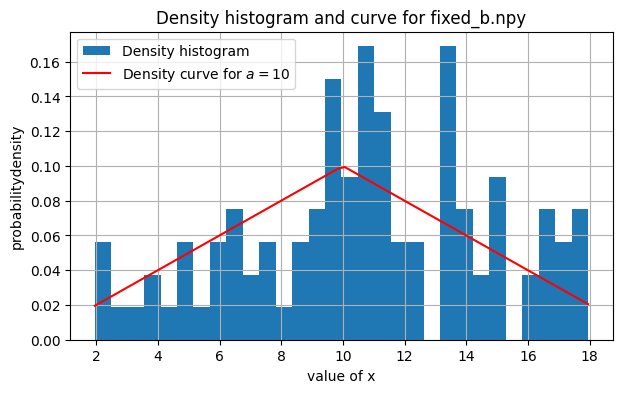

In [4]:
# TODO: answer Question 3, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
def pdf(x, a, b=20):
    if (x < 0 or x > b):
        return 0
    elif (0 <= x and x <= a):
        return (2/b) * (x/a)
    else:  # case where a < x <= b
        return (2/b) * ((b - x)/(b - a))

# Load the data
fixed_b = np.load('fixed_b.npy')

print('fixed_b.npy size:', fixed_b.shape[0])
print('Empirical mean:', np.mean(fixed_b))
print('Median:', np.median(fixed_b))

# Plot density histogram with curve of the pdf 
plt.hist(fixed_b, bins=30, density=True, label='Density histogram')
a_chosen = 10
sorted_fixed_b = np.sort(fixed_b)
pdf_values = [pdf(x, a_chosen) for x in sorted_fixed_b]  # Assuming a=10 for the pdf
plt.plot(sorted_fixed_b, pdf_values, color='red', label='Density curve for $a=10$')
plt.title('Density histogram and curve for fixed_b.npy')
plt.xlabel('value of x')
plt.ylabel('probabilitydensity')
plt.legend();

### Question 4 — Mean and median estimators

Invert the expressions for the population mean and median to derive
$\hat a_{\mathrm{mean}}$ and $\hat a_{\mathrm{median}}$. Implement them and
evaluate them on the sample. Can finite-sample estimates fall outside $(0,b)$?
Use the untruncated formulas in the later MSE comparison and explain this choice.

In [5]:
# TODO: answer Question 4, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
# Mean estimator
display(Markdown(r"""We first invert the formula for the mean:
$ \mu = \frac{a+b}{3} \Leftrightarrow a = 3\mu - b $ """))
def a_mean_est(fixed_b, b=20):
    return 3*np.mean(fixed_b) - b

# Median estimator
display(Markdown(r"""Now let's invert the formula for the median:
- Case 1: When $a > \frac{b}{2}$.  
As explained in question 2, $ m=\sqrt{\frac{a b}{2}} \Leftrightarrow a = \frac{2 m^2}{b} $.
- Case 2: When $a < \frac{b}{2}$.
As explained in question 2, $ m = b - \sqrt{\frac{b(b-a)}{2}} \Leftrightarrow a = b - \frac{2(b-m)^2}{b}$.
- Case 3: When $a = \frac{b}{2}$.
Then $ m = \frac{b}{2} \Leftrightarrow a = \frac{b}{2} $.
"""))

def a_median_est(data, b=20, disp=False):
    median = np.median(data)
    if median > b/2:
        if disp:
            print(f'm is in [0, a]')
        return 2*median**2/b
    elif median < b/2:
        if disp:
            print(f'm is in (a, b]')
        return b - 2*(b - median)**2/b
    else:
        return b/2

# Evaluation on the sample
a_mean_estimator = a_mean_est(fixed_b)
a_median_estimator = a_median_est(fixed_b, disp=True)
print(f'Estimated a using the mean: {a_mean_estimator}')
print(f'Estimated a using the median: {a_median_estimator}')

# Discussion on the interval
display(Markdown(r"""It is indeed possible for the estimates to lie outside the interval $[0,b]$. For example, if the mean is very small, the estimate for $a$ using the mean can be negative. 
For the median (in case 1: $a > b/2$), if it is too large, the estimate for $a$ using the median can be larger than $b$. 
"""))

# Discussion on the truncation
display(Markdown(r"""If we wanted to be sure that our estimates fall within the interval $[0,b]$, we could truncate the estimates.
However, this would modify the bias and MSE of our estimators. Thus, we should stick to the untruncated estimates."""))

We first invert the formula for the mean:
$ \mu = \frac{a+b}{3} \Leftrightarrow a = 3\mu - b $ 

Now let's invert the formula for the median:
- Case 1: When $a > \frac{b}{2}$.  
As explained in question 2, $ m=\sqrt{\frac{a b}{2}} \Leftrightarrow a = \frac{2 m^2}{b} $.
- Case 2: When $a < \frac{b}{2}$.
As explained in question 2, $ m = b - \sqrt{\frac{b(b-a)}{2}} \Leftrightarrow a = b - \frac{2(b-m)^2}{b}$.
- Case 3: When $a = \frac{b}{2}$.
Then $ m = \frac{b}{2} \Leftrightarrow a = \frac{b}{2} $.


m is in [0, a]
Estimated a using the mean: 12.219255228560613
Estimated a using the median: 11.450058658590189


It is indeed possible for the estimates to lie outside the interval $[0,b]$. For example, if the mean is very small, the estimate for $a$ using the mean can be negative. 
For the median (in case 1: $a > b/2$), if it is too large, the estimate for $a$ using the median can be larger than $b$. 


If we wanted to be sure that our estimates fall within the interval $[0,b]$, we could truncate the estimates.
However, this would modify the bias and MSE of our estimators. Thus, we should stick to the untruncated estimates.

### Question 5 — Likelihood and maximum likelihood

Write and plot the log-likelihood $\ell(a;x_1,\ldots,x_n)$ for known $b=20$.
Compute the maximum-likelihood estimate. Check the maximum over a grid or the
sample locations rather than trusting a single local optimizer.

For numerical endpoint handling, optimize over $[\varepsilon b,(1-\varepsilon)b]$
with $\varepsilon=10^{-8}$. Report if the solution reaches a numerical boundary.
Explain why the log-likelihood can have several local maxima.

Maximum log-likelihood occurs at a = 11.35678389246231
The solution is inside the parameter interval.


The log-likelihood function can have multiple local maxima because the pdf changes formula at $x=a$. This can lead to different slopes of the log-likelihood function on either side of $a$, potentially creating multiple peaks in the log-likelihood and the possibility of getting the maximum at a wrong location.

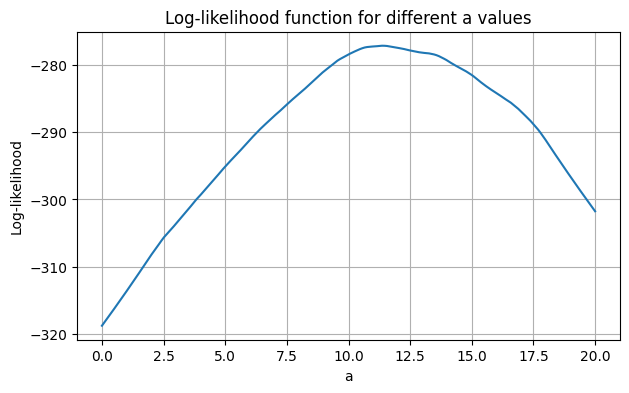

In [6]:
# TODO: answer Question 5, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
def llh(a, data, b=20):
    likelihood = 0
    for x in data:
        likelihood += np.log(pdf(x, a, b))
    return likelihood

# Maximum log-likelihood
b = 20
eps = 1e-8
grid_a = np.linspace(eps*b, (1-eps)*b, 200)

llh_values = [llh(a, fixed_b) for a in grid_a]
max_llh_index = np.argmax(llh_values)
max_llh_a = grid_a[max_llh_index]
print(f'Maximum log-likelihood occurs at a = {max_llh_a}')

# Check if the solution is at the boundary
if np.isclose(max_llh_a, eps*b) or np.isclose(max_llh_a, (1-eps)*b):
    print("The solution reaches a numerical boundary.")
else:
    print("The solution is inside the parameter interval.")

# Plot the log-likelihood
plt.plot(grid_a, llh_values);
plt.title('Log-likelihood function for different a values')
plt.xlabel('a')
plt.ylabel('Log-likelihood');

display(Markdown(r"""The log-likelihood function can have multiple local maxima because the pdf changes formula at $x=a$. This can lead to different slopes of the log-likelihood function on either side of $a$, potentially creating multiple peaks in the log-likelihood and the possibility of getting the maximum at a wrong location."""))

### Question 6 — Bootstrap uncertainty

Use 1,000 nonparametric bootstrap samples of size $n$ to compute percentile 95%
confidence intervals for the mean, median, and maximum-likelihood estimators.
Use the same bootstrap samples for the three estimators. Report the point estimates
and intervals. Explain the frequentist interpretation and whether a unique
integer value of $a$ is established.

In [7]:
# TODO: answer Question 6, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

# Define the function for MLE
def max_llh_est(fixed_b, b=20):
    grid_a = np.linspace(eps*b, (1-eps)*b, 200)
    llh_values = [llh(a, fixed_b) for a in grid_a]
    max_llh_index = np.argmax(llh_values)
    max_llh_a = grid_a[max_llh_index]
    return max_llh_a

# Point estimates for the 3 estimators
a_mean_estimator = a_mean_est(fixed_b)
a_median_estimator = a_median_est(fixed_b)
a_max_llh_estimator = max_llh_est(fixed_b)

print(f'Estimated a using the mean: {a_mean_estimator:.4f}')
print(f'Estimated a using the median: {a_median_estimator:.4f}')
print(f'Estimated a using the MLE: {a_max_llh_estimator:.4f}')

# Produce bootstrap samples
def generate_bootstrap_samples(x, N_rep=1000):
    return np.random.choice(x, size=(N_rep, len(x)), replace=True)

# Compute CI for the 3 estimators using bootstrap samples
def bootstrap_CI(estimator_function, bootstrap_samples):
    estimates = np.array([estimator_function(sample) for sample in bootstrap_samples])
    ci = np.percentile(estimates, [2.5, 97.5])
    return ci

bs_samples = generate_bootstrap_samples(fixed_b, N_rep=1000)

print(f'Confidence interval for the mean estimator: {bootstrap_CI(a_mean_est, bs_samples)}')
print(f'Confidence interval for the median estimator: {bootstrap_CI(a_median_est, bs_samples)}')
print(f'Confidence interval for the MLE estimator: {bootstrap_CI(max_llh_est, bs_samples)}')

display(Markdown(r"""The confidence intervals mean that it contains the true value of $a$ in 95% of the repeated samples and not that the true $a$ is within it with probability 0.95. Thus, we cannot say that $a$ is within the interval for sure.
However, as the 3 different confidence intervals are overlapping, we can say that the true $a$ could probably be somewhere around these intervals. In particular, they all contain the values 11, 12 and 13 which gives us an idea of the value of a.
"""))


Estimated a using the mean: 12.2193
Estimated a using the median: 11.4501
Estimated a using the MLE: 11.3568
Confidence interval for the mean estimator: [ 9.73576408 14.39439187]
Confidence interval for the median estimator: [10.12821096 13.28231388]
Confidence interval for the MLE estimator: [10.05025126 13.77135671]


The confidence intervals mean that it contains the true value of $a$ in 95% of the repeated samples and not that the true $a$ is within it with probability 0.95. Thus, we cannot say that $a$ is within the interval for sure.
However, as the 3 different confidence intervals are overlapping, we can say that the true $a$ could probably be somewhere around these intervals. In particular, they all contain the values 11, 12 and 13 which gives us an idea of the value of a.


### Question 7 — Fisher information and the Cramér–Rao bound

Compute the one-observation Fisher information
$I_1(a)=\mathbb E[(\partial_a\log p(X;a,b))^2]$ for fixed $b$ and interior $a$.
Deduce $I_n(a)$ and the Cramér–Rao variance bound for an unbiased estimator.
Which of the estimators above is known to be unbiased? Explain why the unbiased
bound must not be asserted as a finite-sample MSE bound for every estimator.

In [8]:
# TODO: answer Question 7, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

display(Markdown(r""" 
The Fisher information is given by
$$
I_1(a) = \mathbb{E} \biggr[( \frac{\partial}{\partial a} \log p(x;a,b))^2 \biggr]
$$ 
First, we compute the derivative
- Case 1: $x \in [0,a]$:
$$
log(p(x;a,b)) = log\biggr(\frac{2}{b} \frac{x}{a}\biggr) \Rightarrow \frac{\partial{log(p(x;a,b))}}{\partial a} = \frac{1}{\frac{2}{b}\frac{x}{a}}\cdot -\frac{2}{b}\frac{x}{a^2} = -\frac{1}{a}
$$

- Case 2: $x \in (a,b]$:
$$
log(p(x;a,b)) = log\left(\frac{2}{b} \frac{b-x}{b-a}\right) \\
\Rightarrow \frac{\partial{log(p(x;a,b))}}{\partial a} = \frac{1}{\frac{2}{b}\frac{b-x}{b-a}}\cdot \biggr(-\frac{2}{b}\frac{b-x}{(b-a)^2}\biggr) \cdot (-1)  = \frac{1}{b-a}
$$
Then, we compute the expected value
$$
I_1(a)=\mathbb{E}  \biggr[ \biggr( \frac{\partial}{\partial a} \log p(x;a,b) \biggr)^2\biggr]
= \int_{-\infty}^{\infty} \biggr( \frac{\partial}{\partial a} \log p(x;a,b) \biggr)^2  p(x;a,b) dx\\
\begin{aligned}
&= \int_{0}^{a} \biggr(-\frac{1}{a}\biggr)^2\frac{2}{b}\frac{x}{a}  dx + 
\int_{a}^{b} \biggr(\frac{1}{(b-a)}\biggr)^2 \frac{2}{b}\frac{b-x}{b-a}  dx \\
&= \frac{1}{b}\frac{x^2}{a^3}\biggr\rvert_0^a + 
\frac{1}{(b-a)^3} \frac{2}{b} (bx-\frac{1}{2}x^2)\biggr\rvert_a^b \\
&=\frac{1}{ab} + \frac{1}{b(b-a)} \\ &= \frac{1}{a(b-a)}
\end{aligned}$$
And we deduce the Fisher information $I_n(a) = \sum_{i=1}^{n} I(a) = n\cdot I = \frac{n}{a(b-a)}$

From the Fisher information, we can compute the Cramér-Rao bound for an unbiased estimator
$$
MSE(a) = Var(a) \geq \frac{1}{I_n(a)} = \frac{1}{\frac{n}{a(b-a)}} = \frac{a(b-a)}{n}
$$ 

Now, we know that the mean estimator is unbiased, as 
$$
\mathbb{E}[\hat{a}_{mean}] = \mathbb{E}[3\bar{X}-b] = 3\mathbb{E}[\bar{X}]-b = 3\frac{a+b}{3}-b = a
$$

We cannot use the Cramér-Rao bound for estimators that are potentially biased, such as the median or the MLE. This is because for a biased estimator
$$
MSE(\hat{a}) = Var(\hat{a}) + Bias(\hat{a})^2
$$
The only conclusion we can draw for a all cases is that
$$
MSE(\hat{a}) = Var(\hat{a}) + Bias(\hat{a})^2 \geq \frac{1}{I_n(a)} + Bias(\hat{a})^2
$$
"""))

 
The Fisher information is given by
$$
I_1(a) = \mathbb{E} \biggr[( \frac{\partial}{\partial a} \log p(x;a,b))^2 \biggr]
$$ 
First, we compute the derivative
- Case 1: $x \in [0,a]$:
$$
log(p(x;a,b)) = log\biggr(\frac{2}{b} \frac{x}{a}\biggr) \Rightarrow \frac{\partial{log(p(x;a,b))}}{\partial a} = \frac{1}{\frac{2}{b}\frac{x}{a}}\cdot -\frac{2}{b}\frac{x}{a^2} = -\frac{1}{a}
$$

- Case 2: $x \in (a,b]$:
$$
log(p(x;a,b)) = log\left(\frac{2}{b} \frac{b-x}{b-a}\right) \\
\Rightarrow \frac{\partial{log(p(x;a,b))}}{\partial a} = \frac{1}{\frac{2}{b}\frac{b-x}{b-a}}\cdot \biggr(-\frac{2}{b}\frac{b-x}{(b-a)^2}\biggr) \cdot (-1)  = \frac{1}{b-a}
$$
Then, we compute the expected value
$$
I_1(a)=\mathbb{E}  \biggr[ \biggr( \frac{\partial}{\partial a} \log p(x;a,b) \biggr)^2\biggr]
= \int_{-\infty}^{\infty} \biggr( \frac{\partial}{\partial a} \log p(x;a,b) \biggr)^2  p(x;a,b) dx\\
\begin{aligned}
&= \int_{0}^{a} \biggr(-\frac{1}{a}\biggr)^2\frac{2}{b}\frac{x}{a}  dx + 
\int_{a}^{b} \biggr(\frac{1}{(b-a)}\biggr)^2 \frac{2}{b}\frac{b-x}{b-a}  dx \\
&= \frac{1}{b}\frac{x^2}{a^3}\biggr\rvert_0^a + 
\frac{1}{(b-a)^3} \frac{2}{b} (bx-\frac{1}{2}x^2)\biggr\rvert_a^b \\
&=\frac{1}{ab} + \frac{1}{b(b-a)} \\ &= \frac{1}{a(b-a)}
\end{aligned}$$
And we deduce the Fisher information $I_n(a) = \sum_{i=1}^{n} I(a) = n\cdot I = \frac{n}{a(b-a)}$

From the Fisher information, we can compute the Cramér-Rao bound for an unbiased estimator
$$
MSE(a) = Var(a) \geq \frac{1}{I_n(a)} = \frac{1}{\frac{n}{a(b-a)}} = \frac{a(b-a)}{n}
$$ 

Now, we know that the mean estimator is unbiased, as 
$$
\mathbb{E}[\hat{a}_{mean}] = \mathbb{E}[3\bar{X}-b] = 3\mathbb{E}[\bar{X}]-b = 3\frac{a+b}{3}-b = a
$$

We cannot use the Cramér-Rao bound for estimators that are potentially biased, such as the median or the MLE. This is because for a biased estimator
$$
MSE(\hat{a}) = Var(\hat{a}) + Bias(\hat{a})^2
$$
The only conclusion we can draw for a all cases is that
$$
MSE(\hat{a}) = Var(\hat{a}) + Bias(\hat{a})^2 \geq \frac{1}{I_n(a)} + Bias(\hat{a})^2
$$


### Question 8 — Jeffreys prior and posterior estimation

Derive and normalize Jeffreys prior $\pi_J(a)\propto\sqrt{I_1(a)}$ on $(0,b)$.
Inspect the posterior density near the boundaries: does maximizing it define a
finite interior global MAP estimate? Distinguish MAP from maximum likelihood.

Instead, compute the posterior mean and an equal-tailed 95% credible interval
for `fixed_b.npy`. Numerical integration is sufficient. Hint: the substitution
$a=b\sin^2\theta$, $0<\theta<\pi/2$, removes the prior's integrable endpoint
singularities. Compare the interpretation with Question 6. Check numerical
stability by increasing your integration resolution.

In [9]:
# TODO: answer Question 8, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

display(Markdown(r"""First, we derive Jeffreys prior
$$
\pi_J(a)\propto\sqrt{I_1(a)}  = \frac{1}{\sqrt{a(b-a)}}
$$
Now, for the normalization we need a constant $C$ such that
$$
\int_{0}^{b} C \frac{1}{\sqrt{a(b-a)}} da = 1
$$
Let's compute the integral. For this, we use the following substitution
$$
a = b\sin^2(\theta) \Rightarrow da = 2b\sin(\theta)\cos(\theta)d\theta
$$
And the bound becomes $\theta \in [0, \frac{\pi}{2}]$.
Hence
and $\sqrt{a(b-a)} = \sqrt{b\sin^2(\theta)(b-b\sin^2(\theta))} = b\sin(\theta)\cos(\theta)$
$$
\int_{0}^{b} C \frac{1}{\sqrt{a(b-a)}} da = \int_{0}^{\pi/2} C \frac{1}{\sqrt{b\sin^2(\theta)(b-b\sin^2(\theta))}} 2b\sin(\theta)\cos(\theta)d\theta \\
\begin{aligned}
&= \int_{0}^{\pi/2} C \frac{1}{b\sin(\theta)\cos(\theta)} 2b\sin(\theta)\cos(\theta)d\theta \\
&= \int_{0}^{\pi/2} 2C d\theta = 2C \theta\biggr\rvert_{0}^{\pi/2} = 2C  \frac{\pi}{2} = C\pi
\end{aligned}
$$
Thus $C = \frac{1}{\pi}$. This gives us for the normalized Jeffreys prior
$$
\pi_J(a) = \frac{1}{\pi} \frac{1}{\sqrt{a(b-a)}}
$$

We have that the posterior distribution is given by
$$
p(a|x_1,...,x_n) \propto \pi_J(a)L(a;x_1,...,x_n) \propto \frac{1}{\sqrt{a(b-a)}} \prod_{i=1}^{n} p(x_i;a,b) \\
$$

Now we have that:
- Case 1: $a \to 0^+ $. In this case it means that $x_i > a \forall i$ and thus the posterior density is
$$
p(a|x_1,...,x_n) \propto \frac{1}{\sqrt{a(b-a)}} \prod_{i=1}^{n} \frac{2}{b} \frac{b-x_i}{b-a} \overset{a\to 0^+}{=} \frac{\frac{2}{b} \frac{b-x}{b^2}}{\sqrt{ab}} \to \infty \\
$$
- Case 2: $a \to b^- $. In this case it means that $x_i <= a \forall i$ and thus the posterior density is
$$
p(a|x_1,...,x_n) \propto \frac{1}{\sqrt{a(b-a)}} \prod_{i=1}^{n} \frac{2}{b} \frac{x_i}{a} \overset{a\to b^-}{=} \frac{\frac{2x}{b^2}}{0} \to \infty
$$

Hence in this case the posterior has no finite interior global maximum and a finite interior global MAP estimate cannot be defined.

The MLE can still be defined as a finite interior value because it maximises the likelihood only. The fact that the posterior doesn't have a finite interior global MAP does not imply that the MLE is undefined.
"""))   

# Compute posterior mean and equal-tailed 95% credible interval
def posterior_mean_interval(data, b, n_grid=1000):
    # Create a grid for theta and avoid the endpoints
    epsilon = 1e-10
    theta = np.linspace(epsilon, np.pi/2 - epsilon, n_grid)
    a = b * np.sin(theta)**2

    # Compute likelihood on the grid
    llh_grid = np.array([llh(value, data, b) for value in a])

    # Stabilise likelihood to avoid numerical problems
    llh_stabil = np.exp(llh_grid - np.max(llh_grid))

    # Normalise posterior density in theta
    norm_constant = np.trapezoid(llh_stabil, theta)

    # Compute posterior
    posterior = llh_stabil / norm_constant

    # Compute posterior mean
    posterior_mean = np.trapezoid(a * posterior, theta)

    # Compute posterior CDF
    increments = 0.5 * (llh_stabil[:-1] + llh_stabil[1:]) * np.diff(theta)
    cdf = np.concatenate(([0.0], np.cumsum(increments)))
    cdf /= cdf[-1]

    # Compute 2.5% and 97.5% quantiles
    theta_lower = np.interp(0.025, cdf, theta)
    theta_upper = np.interp(0.975, cdf, theta)

    # Transform quantiles back to a
    lower = b * np.sin(theta_lower)**2
    upper = b * np.sin(theta_upper)**2

    return posterior_mean, lower, upper

print('n_grid=10000:')
mean_post, lower_CI, upper_CI = posterior_mean_interval(fixed_b, b=20, n_grid=10000)
print(f'Posterior mean: {mean_post:.4f}')
print(f'Equal-tailed 95% credible interval: [{lower_CI:.4f}, {upper_CI:.4f}]')

print('\n n_grid=50000:')
mean_post_high, lower_CI_high, upper_CI_high = posterior_mean_interval(fixed_b, b=20, n_grid=50000)
print(f'Posterior mean: {mean_post_high:.4f}')
print(f'Equal-tailed 95% credible interval: [{lower_CI_high:.4f}, {upper_CI_high:.4f}]')

print('Evaluate numerical stability:')
print(f'Difference between means: {abs(mean_post_high - mean_post):.4e}')
print(f'Difference between lower CI: {abs(lower_CI_high - lower_CI):.4e}')
print(f'Difference between upper CI: {abs(upper_CI_high - upper_CI):.4e}')

display(Markdown(r""" 
Compared to question 6, here we have more values in the interval (10 to 13)"""))

First, we derive Jeffreys prior
$$
\pi_J(a)\propto\sqrt{I_1(a)}  = \frac{1}{\sqrt{a(b-a)}}
$$
Now, for the normalization we need a constant $C$ such that
$$
\int_{0}^{b} C \frac{1}{\sqrt{a(b-a)}} da = 1
$$
Let's compute the integral. For this, we use the following substitution
$$
a = b\sin^2(\theta) \Rightarrow da = 2b\sin(\theta)\cos(\theta)d\theta
$$
And the bound becomes $\theta \in [0, \frac{\pi}{2}]$.
Hence
and $\sqrt{a(b-a)} = \sqrt{b\sin^2(\theta)(b-b\sin^2(\theta))} = b\sin(\theta)\cos(\theta)$
$$
\int_{0}^{b} C \frac{1}{\sqrt{a(b-a)}} da = \int_{0}^{\pi/2} C \frac{1}{\sqrt{b\sin^2(\theta)(b-b\sin^2(\theta))}} 2b\sin(\theta)\cos(\theta)d\theta \\
\begin{aligned}
&= \int_{0}^{\pi/2} C \frac{1}{b\sin(\theta)\cos(\theta)} 2b\sin(\theta)\cos(\theta)d\theta \\
&= \int_{0}^{\pi/2} 2C d\theta = 2C \theta\biggr\rvert_{0}^{\pi/2} = 2C  \frac{\pi}{2} = C\pi
\end{aligned}
$$
Thus $C = \frac{1}{\pi}$. This gives us for the normalized Jeffreys prior
$$
\pi_J(a) = \frac{1}{\pi} \frac{1}{\sqrt{a(b-a)}}
$$

We have that the posterior distribution is given by
$$
p(a|x_1,...,x_n) \propto \pi_J(a)L(a;x_1,...,x_n) \propto \frac{1}{\sqrt{a(b-a)}} \prod_{i=1}^{n} p(x_i;a,b) \\
$$

Now we have that:
- Case 1: $a \to 0^+ $. In this case it means that $x_i > a \forall i$ and thus the posterior density is
$$
p(a|x_1,...,x_n) \propto \frac{1}{\sqrt{a(b-a)}} \prod_{i=1}^{n} \frac{2}{b} \frac{b-x_i}{b-a} \overset{a\to 0^+}{=} \frac{\frac{2}{b} \frac{b-x}{b^2}}{\sqrt{ab}} \to \infty \\
$$
- Case 2: $a \to b^- $. In this case it means that $x_i <= a \forall i$ and thus the posterior density is
$$
p(a|x_1,...,x_n) \propto \frac{1}{\sqrt{a(b-a)}} \prod_{i=1}^{n} \frac{2}{b} \frac{x_i}{a} \overset{a\to b^-}{=} \frac{\frac{2x}{b^2}}{0} \to \infty
$$

Hence in this case the posterior has no finite interior global maximum and a finite interior global MAP estimate cannot be defined.

The MLE can still be defined as a finite interior value because it maximises the likelihood only. The fact that the posterior doesn't have a finite interior global MAP does not imply that the MLE is undefined.


n_grid=10000:
Posterior mean: 11.6495
Equal-tailed 95% credible interval: [9.7409, 13.9477]

 n_grid=50000:
Posterior mean: 11.6495
Equal-tailed 95% credible interval: [9.7409, 13.9477]
Evaluate numerical stability:
Difference between means: 8.4651e-09
Difference between lower CI: 1.9062e-06
Difference between upper CI: 2.1950e-06


 
Compared to question 6, here we have more values in the interval (10 to 13)

### Question 9 — Sampling the distribution

Derive an inverse-CDF sampler from Question 2. Implement a vectorized function
`sample_triangular(a, b, size, rng)`, and check its empirical mean and histogram
using 10,000 samples with $a=13,b=20$. Explain why it avoids the repeated rejection
steps of a rejection sampler. Use only interior parameters $0<a<b$.


Let's first invert the CDF. We denote u = F(t) and we observe that we have 2 cases for $t\in [0,a]$ and $t\in (a,b]$. Hence the formula changes at $t=a$ and we have $F(a) = \frac{a^2}{ab} = \frac{a}{b}$ and the new boundary for $u$ is $\frac{a}{b}$. We have
- Case 1: $u \in [0, \frac{a}{b}]$. Then we have $u = \frac{t^2}{ab} \Leftrightarrow t = \sqrt{uab}$
- Case 2: $u \in (\frac{a}{b}, 1]$. Then we have $u = 1-\frac{(b-t)^2}{b(b-a)} \Leftrightarrow t = b - \sqrt{(1-u)b(b-a)}$
Hence the inverse CDF is given by
$$
F^{-1}(u) = \begin{cases} 0 & u < 0\\  \sqrt{uab} & 0\leq u\leq \frac{a}{b}\\ b - \sqrt{(1-u)b(b-a)}&\frac{a}{b}<u\leq 1\\1& u>1 \end{cases}
$$


Mean of the samples: 11.01054533804878


The mean of the samples is close to the theoretical mean $\mu = \frac{minimum + mode + maximum}{3} =\frac{0+a+b}{3} = \frac{13+20}{3} = 11$.
The histogram shows the shape of the triangular distribution, with the peak at $a=13$ and tapering off towards $b=20$. 

Using this method avoids rejection, because we directly sample from the desired distribution using the inverse CDF, which will always give valid samples. The rejection sampling would instead generate candidate samples and reject those that do not meet the criteria.


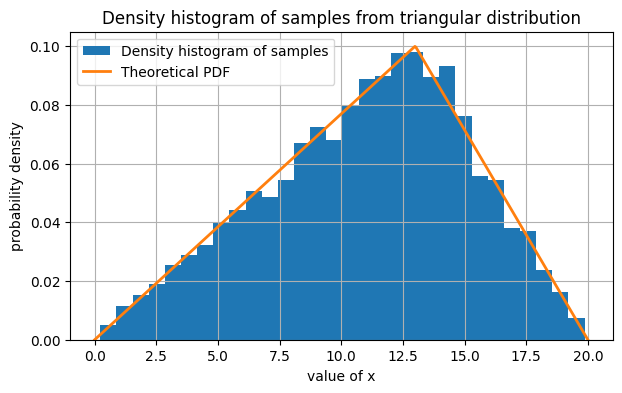

In [10]:
# TODO: answer Question 9, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

display(Markdown(r"""
Let's first invert the CDF. We denote u = F(t) and we observe that we have 2 cases for $t\in [0,a]$ and $t\in (a,b]$. Hence the formula changes at $t=a$ and we have $F(a) = \frac{a^2}{ab} = \frac{a}{b}$ and the new boundary for $u$ is $\frac{a}{b}$. We have
- Case 1: $u \in [0, \frac{a}{b}]$. Then we have $u = \frac{t^2}{ab} \Leftrightarrow t = \sqrt{uab}$
- Case 2: $u \in (\frac{a}{b}, 1]$. Then we have $u = 1-\frac{(b-t)^2}{b(b-a)} \Leftrightarrow t = b - \sqrt{(1-u)b(b-a)}$
Hence the inverse CDF is given by
$$
F^{-1}(u) = \begin{cases} 0 & u < 0\\  \sqrt{uab} & 0\leq u\leq \frac{a}{b}\\ b - \sqrt{(1-u)b(b-a)}&\frac{a}{b}<u\leq 1\\1& u>1 \end{cases}
$$
"""))

# Implementation of the inverse CDF sampling
def sample_triangular(a, b, size, rng):
    if a <= 0 or b <= a:
        raise ValueError("Invalid parameters: 0 <= a < b needed.")
    u = rng.uniform(0, 1, size=size)
    samples = np.zeros(size)
    for i in range(size):
        if u[i] <= a/b:
            samples[i] = np.sqrt(u[i]*a*b)
        else:
            samples[i] = b - np.sqrt((1-u[i])*b*(b-a))
    return samples

# Check the sampling function
samples_q9 = sample_triangular(13, 20, 10000, np.random.default_rng(SEED))
print(f'Mean of the samples: {np.mean(samples_q9)}')

plt.hist(samples_q9, bins=30, density=True, label='Density histogram of samples')

# Theoretical PDF for comparison
x = np.linspace(0, b, 500)
pdf_theorical = np.where(
    x <= 13,
    2 * x / (13 * b),
    2 * (b - x) / (b * (b - 13))
)
plt.plot(x, pdf_theorical, linewidth=2, label="Theoretical PDF")

plt.title('Density histogram of samples from triangular distribution')
plt.xlabel('value of x')
plt.ylabel('probability density')
plt.legend();

display(Markdown(r"""The mean of the samples is close to the theoretical mean $\mu = \frac{minimum + mode + maximum}{3} =\frac{0+a+b}{3} = \frac{13+20}{3} = 11$.
The histogram shows the shape of the triangular distribution, with the peak at $a=13$ and tapering off towards $b=20$. """))

display(Markdown(r"""Using this method avoids rejection, because we directly sample from the desired distribution using the inverse CDF, which will always give valid samples. The rejection sampling would instead generate candidate samples and reject those that do not meet the criteria.
"""))

### Question 10 — Compare the estimators in repeated experiments

Set $b=20$ and $n=1000$. For ten values of $a$ evenly spaced between 1 and 19,
repeat the experiment 300 times. On each sample compute the mean, median, MLE,
and Jeffreys posterior-mean estimates. Reuse the same sample for all estimators.
Plot estimated MSE with Monte Carlo standard errors, together with the unbiased
Cramér–Rao reference. Which estimators perform well, and does the answer depend
on $a$? Do not interpret a small Monte Carlo difference as a universal ranking.
For the posterior mean, 801 quadrature points are sufficient for this experiment;
check selected cases at higher resolution.

a=1.00: MSE Mean=0.175484 (MCSE=0.013855), MSE Median=0.315985 (MCSE=0.027512), MSE MLE=0.027337 (MCSE=0.002478), MSE Jeffreys=0.024850 (MCSE=0.002253)
a=3.00: MSE Mean=0.168923 (MCSE=0.014019), MSE Median=0.259893 (MCSE=0.021629), MSE MLE=0.063333 (MCSE=0.005683), MSE Jeffreys=0.059498 (MCSE=0.005325)
a=5.00: MSE Mean=0.187153 (MCSE=0.014155), MSE Median=0.244120 (MCSE=0.019559), MSE MLE=0.082318 (MCSE=0.007119), MSE Jeffreys=0.079493 (MCSE=0.006405)
a=7.00: MSE Mean=0.155941 (MCSE=0.012380), MSE Median=0.154897 (MCSE=0.012213), MSE MLE=0.093504 (MCSE=0.007895), MSE Jeffreys=0.093283 (MCSE=0.007772)
a=9.00: MSE Mean=0.150528 (MCSE=0.013305), MSE Median=0.119238 (MCSE=0.009948), MSE MLE=0.107907 (MCSE=0.009036), MSE Jeffreys=0.104956 (MCSE=0.008756)
a=11.00: MSE Mean=0.155512 (MCSE=0.014035), MSE Median=0.103854 (MCSE=0.007701), MSE MLE=0.101077 (MCSE=0.008621), MSE Jeffreys=0.099342 (MCSE=0.008137)
a=13.00: MSE Mean=0.182184 (MCSE=0.013470), MSE Median=0.186971 (MCSE=0.014530), MSE ML

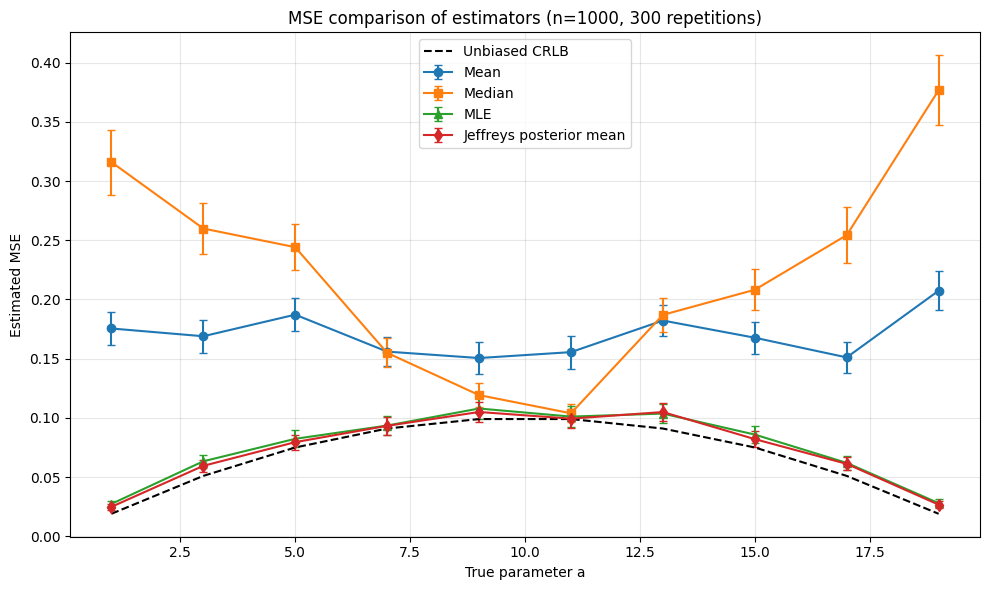


a=1: Mean absolute difference = 0.00001246, Maximum absolute difference = 0.00004629

a=9: Mean absolute difference = 0.00001982, Maximum absolute difference = 0.00008487

a=19: Mean absolute difference = 0.00001265, Maximum absolute difference = 0.00004819



We observe that the MLE and the Jeffreys posterior mean estimations perform better on the tested values than the mean and median estimations. We cannot really choose between the MLE and Jeffreys posterior mean because the difference between the two MSE for the estimates are very small.



In [11]:
# TODO: answer Question 10, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
def llh_grid(a_grid, data, b=20):
    a_grid = np.asarray(a_grid)
    data = np.asarray(data)

    left = data[None, :] <= a_grid[:, None]

    log_density = np.where(
        left,
        np.log(2 * data[None, :] / (a_grid[:, None] * b)),
        np.log(
            2 * (b - data[None, :]) /
            (b * (b - a_grid[:, None]))
        )
    )

    return np.sum(log_density, axis=1)


def max_llh_est_grid(data, b=20):
    eps=1e-8
    lower_bound = eps*b
    upper_bound = (1 - eps) * b
    possibilities = np.unique(np.concatenate((
        [lower_bound, upper_bound],
        data[(data >= lower_bound) & (data <= upper_bound)]
    )))
    llh_values = llh_grid(possibilities, data, b)
    max_llh_index = np.argmax(llh_values)
    max_llh_a = possibilities[max_llh_index]
    return max_llh_a


def jeff_post(data, a_grid, theta_grid, b=20):
    # Compute likelihood on the grid
    llh_a_grid = llh_grid(a_grid, data, b)

    # Stabilise likelihood to avoid numerical problems
    llh_stabil = np.exp(llh_a_grid - np.max(llh_a_grid))

    # Normalise posterior density in theta
    norm_constant = np.trapezoid(llh_stabil, theta_grid)

    # Compute posterior
    posterior = llh_stabil / norm_constant

    # Compute posterior mean
    posterior_mean = np.trapezoid(
        a_grid * posterior, theta_grid
    )

    return posterior_mean


b = 20
n = 1000
a_values = np.linspace(1, 19, 10)
N_rep = 300
rng = np.random.default_rng(SEED)

# Posterior quadrature grid (801 points)
theta_grid = np.linspace(0, np.pi/2, 801+2)[1:-1]
a_grid = b * np.sin(theta_grid)**2

# Store MSE and Monte Carlo standard errors
mse_mean_all = []
mse_median_all = []
mse_mle_all = []
mse_jeff_all = []

mcse_mean_all = []
mcse_median_all = []
mcse_mle_all = []
mcse_jeff_all = []

# Store selected samples for quadrature check
selected_samples = {}

for a in a_values:

    mse_mean = []
    mse_median = []
    mse_mle = []
    mse_jeff = []

    for _ in range(N_rep):

        # Generate samples
        samples = sample_triangular(a, b, n, rng)

        # Calculate estimates using the same sample
        est_mean = a_mean_est(samples, b)
        est_median = a_median_est(samples, b)
        est_mle = max_llh_est_grid(samples, b)
        est_jeff = jeff_post(samples, a_grid, theta_grid, b)

        # Calculate squared errors
        mse_mean.append((est_mean - a)**2)
        mse_median.append((est_median - a)**2)
        mse_mle.append((est_mle - a)**2)
        mse_jeff.append((est_jeff - a)**2)

        # Save samples for selected values of a
        if np.isclose(a, 1) or np.isclose(a, 9) or np.isclose(a, 19):
            selected_samples.setdefault(a, []).append(samples)

    # Average MSE over repetitions
    avg_mse_mean = np.mean(mse_mean)
    avg_mse_median = np.mean(mse_median)
    avg_mse_mle = np.mean(mse_mle)
    avg_mse_jeff = np.mean(mse_jeff)

    # Calculate Monte Carlo standard errors
    mcse_mean = np.std(mse_mean, ddof=1) / np.sqrt(N_rep)
    mcse_median = np.std(mse_median, ddof=1) / np.sqrt(N_rep)
    mcse_mle = np.std(mse_mle, ddof=1) / np.sqrt(N_rep)
    mcse_jeff = np.std(mse_jeff, ddof=1) / np.sqrt(N_rep)

    # Store results
    mse_mean_all.append(avg_mse_mean)
    mse_median_all.append(avg_mse_median)
    mse_mle_all.append(avg_mse_mle)
    mse_jeff_all.append(avg_mse_jeff)

    mcse_mean_all.append(mcse_mean)
    mcse_median_all.append(mcse_median)
    mcse_mle_all.append(mcse_mle)
    mcse_jeff_all.append(mcse_jeff)

    print(
        f'a={a:.2f}: '
        f'MSE Mean={avg_mse_mean:.6f} (MCSE={mcse_mean:.6f}), '
        f'MSE Median={avg_mse_median:.6f} (MCSE={mcse_median:.6f}), '
        f'MSE MLE={avg_mse_mle:.6f} (MCSE={mcse_mle:.6f}), '
        f'MSE Jeffreys={avg_mse_jeff:.6f} (MCSE={mcse_jeff:.6f})'
    )

# Plot MSE with Monte Carlo standard errors

crlb = a_values * (b - a_values) / n

plt.figure(figsize=(10, 6))

plt.errorbar(
    a_values, mse_mean_all, yerr=mcse_mean_all,
    marker='o', capsize=3, label='Mean'
)
plt.errorbar(
    a_values, mse_median_all, yerr=mcse_median_all,
    marker='s', capsize=3, label='Median'
)
plt.errorbar(
    a_values, mse_mle_all, yerr=mcse_mle_all,
    marker='^', capsize=3, label='MLE'
)
plt.errorbar(
    a_values, mse_jeff_all, yerr=mcse_jeff_all,
    marker='d', capsize=3, label='Jeffreys posterior mean'
)
plt.plot(
    a_values, crlb,
    'k--', label='Unbiased CRLB'
)

plt.xlabel('True parameter a')
plt.ylabel('Estimated MSE')
plt.title('MSE comparison of estimators (n=1000, 300 repetitions)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Check Jeffreys posterior mean at higher resolution

theta_grid_high = np.linspace(0, np.pi/2, 3203)[1:-1]
a_grid_high = b * np.sin(theta_grid_high)**2

for a in [1, 9, 19]:

    differences = []

    for samples in selected_samples[a]:

        posterior_801 = jeff_post(
            samples, a_grid, theta_grid, b
        )

        posterior_high = jeff_post(
            samples, a_grid_high, theta_grid_high, b
        )

        differences.append(abs(posterior_801 - posterior_high))

    print(
        f'\na={a}: '
        f'Mean absolute difference = {np.mean(differences):.8f}, '
        f'Maximum absolute difference = {np.max(differences):.8f}'
    )

display(Markdown(r"""
We observe that the MLE and the Jeffreys posterior mean estimations perform better on the tested values than the mean and median estimations. We cannot really choose between the MLE and Jeffreys posterior mean because the difference between the two MSE for the estimates are very small.

"""))

Alex has changed the code. In the next questions, `full.npy` contains a new sample
with both $a$ and $b$ unknown. Neither parameter need equal the earlier value.
Continue treating parameters as continuous before discussing the integer code.

### Question 11 — Joint maximum-likelihood estimation

Load `full.npy`, report its size, and plot a density histogram. Estimate both
parameters by maximizing the likelihood under $0<a<b\le99$ and $b>\max_i x_i$.
Check numerical feasibility and compare several candidate values or starts.
Hint: for each fixed $b$, reuse the candidate-location method from Question 5,
then numerically maximize the resulting profile likelihood over $b$.

full.npy size: 10000


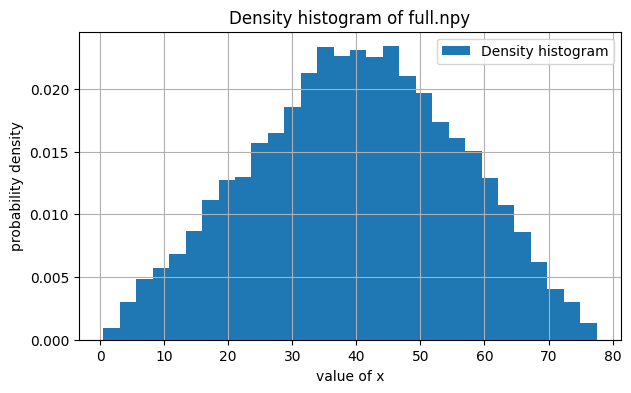


Maximum likelihood estimates:
Estimated a: 41.59517113282544
Estimated b: 77.91889553469497
Maximum log-likelihood: -41648.50409468709

Best candidates:
1. a = 41.595171, b = 77.918896, log-likelihood = -41648.504095
2. a = 41.776547, b = 77.500096, log-likelihood = -41664.577357
3. a = 32.785281, b = 99.000000, log-likelihood = -42697.073865

Feasibility checks:
a > 0: True
a < b: True
b <= 99: True
b > max(x): True
All observations are inside the support: True


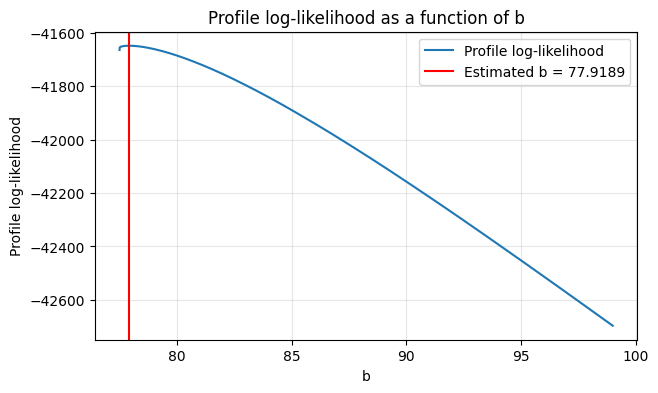

In [12]:
# TODO: answer Question 11, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
full = np.asarray(np.load('full.npy'), dtype=float).ravel()
n = len(full)
x_sorted = np.sort(full)
xmin = x_sorted[0]
xmax = x_sorted[-1]
print('full.npy size:', n)

plt.hist(full, bins=30, density=True, label='Density histogram')
plt.title('Density histogram of full.npy')
plt.xlabel('value of x')
plt.ylabel('probability density')
plt.legend()
plt.show()

# Prepare candidate values for a
if not (0 < xmin and xmax < 99):
    raise ValueError('All observations must satisfy 0 < x < 99')

a_candidates = np.unique(x_sorted)

# Precompute sums
prefix_log_x = np.concatenate(
    ([0.0], np.cumsum(np.log(x_sorted)))
)
k = np.searchsorted(
    x_sorted, a_candidates, side='right'
)

# Define the profile log-likelihood
def profile_loglik(b):
    # for fixed b, maximize over a
    if not (xmax < b <= 99):
        return -np.inf

    log_b_minus_x = np.log(b - x_sorted)

    prefix_log_b_minus_x = np.concatenate(
        ([0.0], np.cumsum(log_b_minus_x))
    )

    loglik_values = (
        n * np.log(2 / b)
        + prefix_log_x[k]
        - k * np.log(a_candidates)
        + prefix_log_b_minus_x[-1]
        - prefix_log_b_minus_x[k]
        - (n - k) * np.log(b - a_candidates)
    )
    return np.max(loglik_values)

# Search for the best possible b
from scipy.optimize import minimize_scalar

b_lower = xmax + min(
    1e-8 * max(1.0, abs(xmax)),
    0.5 * (99 - xmax)
)
b_upper = 99.0
if b_lower >= b_upper:
    raise ValueError('No feasible interval for b')

# Evaluate the profile log-likelihood on a grid
b_grid = np.linspace(b_lower, b_upper, 4001)

profile_values = np.array([
    profile_loglik(b) for b in b_grid
])

# Identify local maxima
local_maxima = np.where(
    (profile_values[1:-1] >= profile_values[:-2])
    & (profile_values[1:-1] >= profile_values[2:])
)[0] + 1

# Refine each local maximum
candidate_b_results = [
    (b_grid[0], profile_values[0]),
    (b_grid[-1], profile_values[-1])
]

for index in local_maxima:

    result = minimize_scalar(
        lambda b: -profile_loglik(b),
        bounds=(b_grid[index - 1], b_grid[index + 1]),
        method='bounded',
        options={'xatol': 1e-10}
    )

    candidate_b_results.append(
        (result.x, -result.fun)
    )

# Select the best combination of a and b
b_hat, max_loglik = max(
    candidate_b_results,
    key=lambda result: result[1]
)

# Find the optimal a for the estimated b
log_b_minus_x = np.log(b_hat - x_sorted)
prefix_log_b_minus_x = np.concatenate(
    ([0.0], np.cumsum(log_b_minus_x))
)

loglik_a = (
    n * np.log(2 / b_hat)
    + prefix_log_x[k]
    - k * np.log(a_candidates)
    + prefix_log_b_minus_x[-1]
    - prefix_log_b_minus_x[k]
    - (n - k) * np.log(b_hat - a_candidates)
)
a_hat = a_candidates[np.argmax(loglik_a)]

# Display the maximum likelihood estimates
print('\nMaximum likelihood estimates:')
print('Estimated a:', a_hat)
print('Estimated b:', b_hat)
print('Maximum log-likelihood:', max_loglik)

# Display the five best candidate combinations
print('\nBest candidates:')

# Sort candidate solutions by log-likelihood
sorted_results = sorted(
    candidate_b_results,
    key=lambda result: result[1],
    reverse=True
)

best_results = []
for b_value, ll_value in sorted_results:
    if any(abs(b_value - old_b) < 1e-7
           for old_b, _, _ in best_results):
        continue

    log_terms = np.log(b_value - x_sorted)

    prefix_terms = np.concatenate(
        ([0.0], np.cumsum(log_terms))
    )

    likelihoods = (
        n * np.log(2 / b_value)
        + prefix_log_x[k]
        - k * np.log(a_candidates)
        + prefix_terms[-1]
        - prefix_terms[k]
        - (n - k) * np.log(b_value - a_candidates)
    )

    best_a = a_candidates[np.argmax(likelihoods)]

    best_results.append(
        (b_value, best_a, ll_value)
    )

    if len(best_results) == 5:
        break

for i, (b_value, a_value, ll_value) in enumerate(
    best_results, start=1
):
    print(
        f'{i}. a = {a_value:.6f}, '
        f'b = {b_value:.6f}, '
        f'log-likelihood = {ll_value:.6f}'
    )

# Feasibility checks
print('\nFeasibility checks:')
print('a > 0:', a_hat > 0)
print('a < b:', a_hat < b_hat)
print('b <= 99:', b_hat <= 99)
print('b > max(x):', b_hat > xmax)
print('All observations are inside the support:', np.all((full > 0) & (full < b_hat)))

# Plot the profile log-likelihood
plt.plot(b_grid, profile_values,label='Profile log-likelihood')
plt.axvline(b_hat, color='red', label=f'Estimated b = {b_hat:.4f}')
plt.xlabel('b')
plt.ylabel('Profile log-likelihood')
plt.title('Profile log-likelihood as a function of b')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Question 12 — Joint uncertainty and the code

Use 300 nonparametric bootstrap replicates to obtain marginal percentile 95%
intervals for $a$ and $b$ (you may increase this number). Display the bootstrap
estimates together in a scatter plot. Give a plausible integer code, list the
integer pairs inside the two marginal intervals, and explain why these intervals
do not guarantee unique or joint 95% recovery. Discuss the additional caution
needed when a parameter controls the support of a distribution.

Original MLE estimates:
a = 41.59517113282544
b = 77.91889883929755

95% marginal percentile intervals:
a: [40.668019, 42.314053]
b: [77.592900,78.225967]


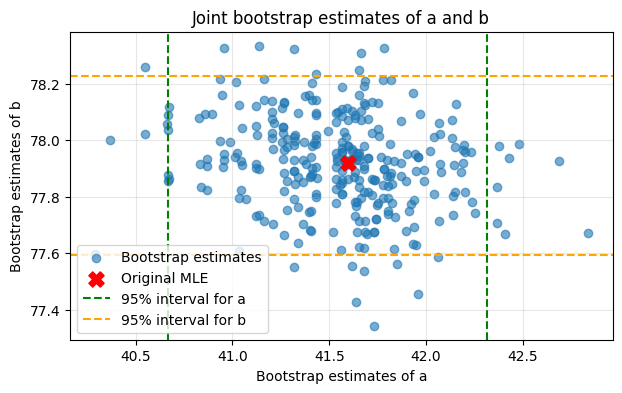


Integer pairs inside both marginal intervals:
(41, 78)
(42, 78)

Plausible integer pair:
a = 42
b = 78



The two 95% intervals do not guarantee joint 95% recovery. 
The probability that both parameters both lay inside their intervals depends on their joint distribution and their correlation. 

Regarding the caution when a parameter controls the support of the distributon, we must exercise caution for b. This is because b forces the samples to be inferior to it (because it's the upper boundary).
In this case, the uncertainty of the upper boundary is not well represented by the bootstrap samples.


In [13]:
# TODO: answer Question 12, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
def estimate_mle(sample):

    sample = np.sort(np.asarray(sample, dtype=float).ravel())

    n_sample = len(sample)
    xmax = sample[-1]

    a_candidates = np.unique(sample)

    prefix_log_x = np.concatenate(
        ([0.0], np.cumsum(np.log(sample)))
    )

    k = np.searchsorted(
        sample, a_candidates, side='right'
    )

    def profile_loglik(b):

        if not (xmax < b <= 99):
            return -np.inf

        log_b_minus_x = np.log(b - sample)

        prefix_log_b_minus_x = np.concatenate(
            ([0.0], np.cumsum(log_b_minus_x))
        )

        loglik_values = (
            n_sample * np.log(2 / b)
            + prefix_log_x[k]
            - k * np.log(a_candidates)
            + prefix_log_b_minus_x[-1]
            - prefix_log_b_minus_x[k]
            - (n_sample - k) * np.log(b - a_candidates)
        )

        return np.max(loglik_values)

    # Search over possible values of b
    eps = max(1e-8, 1e-8 * abs(xmax))
    b_lower = xmax + eps
    b_upper = 99.0

    if b_lower >= b_upper:
        raise ValueError('No feasible value of b')

    b_grid = np.linspace(b_lower, b_upper, 2001)

    profile_values = np.array([
        profile_loglik(b) for b in b_grid
    ])

    # Find local maxima
    local_maxima = np.where(
        (profile_values[1:-1] >= profile_values[:-2])
        & (profile_values[1:-1] >= profile_values[2:])
    )[0] + 1

    candidates = [
        (b_grid[0], profile_values[0]),
        (b_grid[-1], profile_values[-1])
    ]

    # Refine each local maximum
    for index in local_maxima:

        result = minimize_scalar(
            lambda b: -profile_loglik(b),
            bounds=(
                b_grid[index - 1],
                b_grid[index + 1]
            ),
            method='bounded',
            options={'xatol': 1e-9}
        )

        candidates.append((result.x, -result.fun))

    # Select the best value of b, find a
    b_hat, max_ll = max(
        candidates,
        key=lambda result: result[1]
    )

    log_b_minus_x = np.log(b_hat - sample)

    prefix_log_b_minus_x = np.concatenate(
        ([0.0], np.cumsum(log_b_minus_x))
    )

    loglik_a = (
        n_sample * np.log(2 / b_hat)
        + prefix_log_x[k]
        - k * np.log(a_candidates)
        + prefix_log_b_minus_x[-1]
        - prefix_log_b_minus_x[k]
        - (n_sample - k) * np.log(b_hat - a_candidates)
    )

    a_hat = a_candidates[np.argmax(loglik_a)]

    return a_hat, b_hat


# Calculate original MLE estimates
a_hat, b_hat = estimate_mle(full)
print('Original MLE estimates:')
print('a =', a_hat)
print('b =', b_hat)

# Generate 300 bootstrap samples
B = 300
rng = np.random.default_rng(42)
bootstrap_a = []
bootstrap_b = []

for i in range(B):
    bootstrap_sample = rng.choice(
        full,
        size=n,
        replace=True
    )
    try:
        a_boot, b_boot = estimate_mle(bootstrap_sample)
        bootstrap_a.append(a_boot)
        bootstrap_b.append(b_boot)

    except ValueError:
        print('Bootstrap replicate failed:', i + 1)
bootstrap_a = np.asarray(bootstrap_a)
bootstrap_b = np.asarray(bootstrap_b)

# Calculate marginal percentile 95% intervals
a_interval = np.percentile(bootstrap_a, [2.5, 97.5])
b_interval = np.percentile(bootstrap_b, [2.5, 97.5])
print('\n95% marginal percentile intervals:')

print(
    f'a: [{a_interval[0]:.6f}, '
    f'{a_interval[1]:.6f}]'
)
print(
    f'b: [{b_interval[0]:.6f},'
    f'{b_interval[1]:.6f}]'
)

# Scatter plot of bootstrap estimates
plt.scatter(
    bootstrap_a,
    bootstrap_b,
    alpha=0.6,
    label='Bootstrap estimates'
)
plt.scatter(
    a_hat,
    b_hat,
    color='red',
    marker='X',
    s=120,
    label='Original MLE'
)
plt.axvline(
    a_interval[0],
    color='green',
    linestyle='--',
    label='95% interval for a'
)
plt.axvline(
    a_interval[1],
    color='green',
    linestyle='--'
)
plt.axhline(
    b_interval[0],
    color='orange',
    linestyle='--',
    label='95% interval for b'
)
plt.axhline(
    b_interval[1],
    color='orange',
    linestyle='--'
)
plt.xlabel('Bootstrap estimates of a')
plt.ylabel('Bootstrap estimates of b')
plt.title('Joint bootstrap estimates of a and b')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Find integer pairs inside both intervals
a_integers = range(
    int(np.ceil(a_interval[0])),
    int(np.floor(a_interval[1])) + 1
)
b_integers = range(
    int(np.ceil(b_interval[0])),
    int(np.floor(b_interval[1])) + 1
)
integer_pairs = [
    (a, b)
    for a in a_integers
    for b in b_integers
    if 0 < a < b <= 99
]
print('\nInteger pairs inside both marginal intervals:')
if integer_pairs:
    for pair in integer_pairs:
        print(pair)
else:
    print('There are no admissible integer pairs found')

# Select a plausible integer pair
if integer_pairs:
    # Choose the pair closest to the original MLE
    plausible_pair = min(
        integer_pairs,
        key=lambda pair: (
            (pair[0] - a_hat)**2
            + (pair[1] - b_hat)**2
        )
    )
    print('\nPlausible integer pair:')
    print('a =', plausible_pair[0])
    print('b =', plausible_pair[1])
else:
    print('\nNo plausible integer pair found inside both intervals')

display(Markdown(r"""
The two 95% intervals do not guarantee joint 95% recovery. 
The probability that both parameters both lay inside their intervals depends on their joint distribution and their correlation. 

Regarding the caution when a parameter controls the support of the distributon, we must exercise caution for b. This is because b forces the samples to be inferior to it (because it's the upper boundary).
In this case, the uncertainty of the upper boundary is not well represented by the bootstrap samples.
"""))

### Question 13 — Joint moment estimation (optional)

Can the population mean and median identify $(a,b)$? Derive candidate solutions
for both median branches, check the parameter constraints, and try them on
`full.npy`. Explain why finite-sample inversion can be unstable or inadmissible.

In [14]:
# TODO: answer Question 13, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

display(Markdown(r"""
### Question 13 — Joint moment estimation

Remember the median and mean values that we discussed in earlier question.

If now we use $r=a/b$, the mean equation becomes:
$$
b=\frac{3\mu}{1+r},
\qquad
a=\frac{3\mu r}{1+r}.
$$

Now let's solve for both cases:
- Case 1: $r \in (0, 1/2)$. In this case, we have:
$$
a = \frac{3\mu \pm \sqrt{9\mu^2 - 8 m^2}}{2}, \qquad b = 3\mu - a
$$
- Case 2: $r \in (1/2, 1)$. In this case, we have:
$$
b = \frac{2m^2}{4m-3\mu}, \qquad a = 3\mu - b
$$

"""))

mu = np.mean(full)
m = np.median(full)

print("Sample mean:", mu)
print("Sample median:", m)

# case 1: median m <= a
print("\ncase 1: m <= a")
discriminant = 9 * mu**2 - 8 * m**2

solutions = []
if discriminant >= 0:
    sqrt_discriminant = np.sqrt(discriminant)
    # Two possible quadratic solutions
    a_values = [
        (3 * mu + sqrt_discriminant) / 2,
        (3 * mu - sqrt_discriminant) / 2
    ]
    for a in a_values:
        b = 3 * mu - a
        valid = (
            0 < a < b <= 99
            and m <= a
        )
        print(f"\na = {a:.6f}")
        print(f"b = {b:.6f}")
        print("Admissible:", valid)
        if valid:
            solutions.append((a, b, "case 1"))
else:
    print("No real solutions for case 1.")

# case 2: median m > a
print("\ncase 2: m > a")
denominator = 4 * m - 3 * mu

if abs(denominator) > 1e-12:
    b = 2 * m**2 / denominator
    a = 3 * mu - b
    valid = (
        0 < a < b <= 99
        and m > a
    )
    print(f"\na = {a:.6f}")
    print(f"b = {b:.6f}")
    print("Admissible:", valid)
    if valid:
        solutions.append((a, b, "case 2"))
else:
    print("No finite solution for case 2.")

print("\nFINAL ADMISSIBLE MOMENT ESTIMATES")
if solutions:
    for i, (a, b, branch) in enumerate(
        solutions, start=1
    ):
        print(f"\nCandidate {i} ({branch})")
        print(f"a = {a:.6f}")
        print(f"b = {b:.6f}")
else:
    print("No admissible solutions found.")

display(Markdown(r"""
Using the true population moments, these equations identify the pair $(a,b)$. We keep the solution that satisfies the constraints associated with its branch. At $a=b/2$, the two branches join each other.

However, when we use the empirical mean and median computed from the full data, the inversion can give no admissible solution, because these statistics change across samples. It can also possibly become numerically unstable when the discriminant or denominator is close to zero.
"""))


### Question 13 — Joint moment estimation

Remember the median and mean values that we discussed in earlier question.

If now we use $r=a/b$, the mean equation becomes:
$$
b=\frac{3\mu}{1+r},
\qquad
a=\frac{3\mu r}{1+r}.
$$

Now let's solve for both cases:
- Case 1: $r \in (0, 1/2)$. In this case, we have:
$$
a = \frac{3\mu \pm \sqrt{9\mu^2 - 8 m^2}}{2}, \qquad b = 3\mu - a
$$
- Case 2: $r \in (1/2, 1)$. In this case, we have:
$$
b = \frac{2m^2}{4m-3\mu}, \qquad a = 3\mu - b
$$



Sample mean: 39.8411270175782
Sample median: 40.1270620785113

case 1: m <= a

a = 78.499285
b = 41.024096
Admissible: False

a = 41.024096
b = 78.499285
Admissible: True

case 2: m > a

a = 40.948960
b = 78.574421
Admissible: False

FINAL ADMISSIBLE MOMENT ESTIMATES

Candidate 1 (case 1)
a = 41.024096
b = 78.499285



Using the true population moments, these equations identify the pair $(a,b)$. We keep the solution that satisfies the constraints associated with its branch. At $a=b/2$, the two branches join each other.

However, when we use the empirical mean and median computed from the full data, the inversion can give no admissible solution, because these statistics change across samples. It can also possibly become numerically unstable when the discriminant or denominator is close to zero.


## Part II — Supervised learning

We now study a separate problem: classifying images of people with and without
a face mask. The aim is to compare simple supervised models and understand how
additional, class-biased data affect learning. This is an educational benchmark,
not a validated deployment system.

The bundled files follow the current 2026 preprocessing rule, with fixed seeds
and exact duplicate images removed before splitting:
- `data/train.npz`: a small labelled sample from the source training partition;
- `data/extra.npz`: additional labelled images, introduced in Question 21;
- `data/test.npz`: a fixed final test partition; leave it unopened until Question 29.

Images are stored as 128×128 RGB arrays in channel-first order `(3, 128, 128)`.
Labels are **0 = with mask**, **1 = without mask**. To make repeated fitting practical,
the provided `image_features` computes fixed 4×4 pixel-block averages, yielding
32×32 RGB images, scaled to [0,1] and flattened to 3,072 features. It learns nothing
from the data. All models and the evaluator use this same representation.

Use an internal training/validation split of `train.npz`. Hyperparameters are
chosen by five-fold cross-validation on the internal training portion. The small
validation set supports development comparisons; it is not the final test set.
Fit scalers only inside training folds. Keep validation and final test observations
out of resampling and fitting. Use **balanced accuracy** as the primary selection
metric and report ordinary accuracy as well. For two classes, balanced accuracy
is the average of the two class recalls. This supports the later imbalance study.

The local final test is accessible, not secret. Evaluate it only after freezing
your choices. Do not claim hidden-test guarantees or select a new model after
seeing final test scores. Model rankings are empirical results, not required answers.

The `search` helper below uses `GridSearchCV` to try different combinations of
hyperparameters and select the one with the best mean cross-validation score
(here, balanced accuracy).

In [15]:
# PROVIDED: data access and deterministic feature representation.
from evaluation import load_file, image_features, scores, evaluate
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             recall_score, confusion_matrix, ConfusionMatrixDisplay)

images, labels = load_file("train")
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy"}

def search(model, grid, X, y):
    # One worker limits peak memory; randomness is set explicitly in estimators.
    return GridSearchCV(model, grid, scoring=SCORING, refit="balanced_accuracy",
                        cv=CV, n_jobs=1, error_score="raise", return_train_score=True).fit(X, y)

### Question 14 — Explore the image dataset

Report the image-array shape, pixel range, and class counts. Plot six labelled
images. Is this small dataset approximately balanced? Explain why label counts
matter when interpreting ordinary accuracy.

Shape of images array: (185, 3, 128, 128)


The shape of the images array is (number of images, number of channels, height, width).
Thus we have 185 images with 3 channels (RGB) each, and the height and width of each image is 128 pixels.

Shape of six_images array: (6, 3, 128, 128)
Possible image labels: [0 1]


As there are 3 images labelled 0 and 3 images labelled 1, we can say that the dataset is balanced.

Label count matter, because if the dataset was unbalanced, the model could be biased towards the majority class. This can lead to a bad model performance on the minority class. For a balanced dataset, the model has an equal opportunity to learn from both classes, which generally allows for good classification performance across all classes.


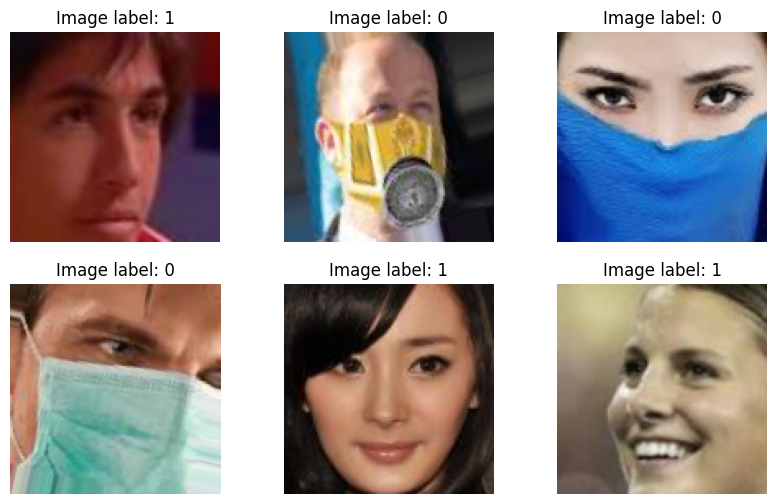

In [16]:
# TODO: answer Question 14, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
print('Shape of images array:', images.shape)

display(Markdown(r"""The shape of the images array is (number of images, number of channels, height, width).
Thus we have 185 images with 3 channels (RGB) each, and the height and width of each image is 128 pixels."""))

six_images = images[:6]
print('Shape of six_images array:', six_images.shape)
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for i, ax in enumerate(axes.flatten()):
    image = np.transpose(six_images[i], (1, 2, 0))  # Convert from (C, H, W) to (H, W, C)
    ax.imshow(image)
    ax.set_title(f'Image label: {labels[i]}')
    ax.axis('off')

print('Possible image labels:', np.unique(labels))

display(Markdown(r"""As there are 3 images labelled 0 and 3 images labelled 1, we can say that the dataset is balanced.

Label count matter, because if the dataset was unbalanced, the model could be biased towards the majority class. This can lead to a bad model performance on the minority class. For a balanced dataset, the model has an equal opportunity to learn from both classes, which generally allows for good classification performance across all classes.
"""))

### Question 15 — Feature vectors, split, and baseline

Use `image_features` and report the feature-array shape. Make a stratified 80/20
training/validation split with `random_state=SEED`. Check both class counts.
Fit a majority-class dummy classifier and report training and validation accuracy
and balanced accuracy. Explain why flattening preserves pixel values but does not
give these models explicit spatial structure.

In [17]:
# TODO: answer Question 15, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
features = image_features(images)
print('Shape of the features array:', features.shape)

display(Markdown(r"""The shape of the features array is (number of images, number of features).
Thus we have 185 images and 3072 features extracted from each image."""))

X_train, X_val, y_train, y_val = train_test_split(features, labels, test_size=0.2, random_state=SEED, stratify=labels)

print("Training class counts:", np.unique(y_train, return_counts=True))

print("Validation class counts:", np.unique(y_val, return_counts=True))

display(Markdown(r""" We conclude that we have a quite balanced dataset."""))

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

dummy_train_scores = scores(dummy, X_train, y_train)
dummy_val_scores = scores(dummy, X_val, y_val)

print(f'Dummy classifier accuracy on training set: {dummy_train_scores['accuracy']:.4f}')
print(f'Dummy classifier accuracy on validation set: {dummy_val_scores['accuracy']:.4f}')
print(f'Dummy classifier balanced accuracy on training set: {dummy_train_scores['balanced_accuracy']:.4f}')
print(f'Dummy classifier balanced accuracy on validation set: {dummy_val_scores['balanced_accuracy']:.4f}')

display(Markdown(r"""Flattening preserves all of the pixel information, but it doesn't preserve the spatial arrangement of the pixels. This is because without it there is a certain 2D structure but when flattened, it's only a 1D vector. Thus the spatial information is lost."""))

Shape of the features array: (185, 3072)


The shape of the features array is (number of images, number of features).
Thus we have 185 images and 3072 features extracted from each image.

Training class counts: (array([0, 1]), array([79, 69]))
Validation class counts: (array([0, 1]), array([20, 17]))


 We conclude that we have a quite balanced dataset.

Dummy classifier accuracy on training set: 0.5338
Dummy classifier accuracy on validation set: 0.5405
Dummy classifier balanced accuracy on training set: 0.5000
Dummy classifier balanced accuracy on validation set: 0.5000


Flattening preserves all of the pixel information, but it doesn't preserve the spatial arrangement of the pixels. This is because without it there is a certain 2D structure but when flattened, it's only a 1D vector. Thus the spatial information is lost.

### Question 16 — Logistic Regression and regularization

Fit Logistic Regression with $\ell_1$ and $\ell_2$ penalties, initially using $C=1$.
Use a `StandardScaler` pipeline and a solver supporting the chosen penalty.
Report training and validation metrics. Explain the difference between the two
penalties and why a single split cannot establish a universal winner.

In [18]:
# TODO: answer Question 16, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
logistic_l1 = make_pipeline(
    StandardScaler(), 
    LogisticRegression(random_state=SEED, penalty='l1', C=1.0, solver='liblinear')
)
logistic_l2 = make_pipeline(
    StandardScaler(), 
    LogisticRegression(random_state=SEED, penalty='l2', C=1.0, solver='liblinear')
)
logistic_l1.fit(X_train, y_train)
logistic_l2.fit(X_train, y_train)

logistic_l1_train_scores = scores(logistic_l1, X_train, y_train)
logistic_l1_val_scores = scores(logistic_l1, X_val, y_val)

logistic_l2_train_scores = scores(logistic_l2, X_train, y_train)
logistic_l2_val_scores = scores(logistic_l2, X_val, y_val)

print(f'Logistic regression (L1) accuracy on training set: {logistic_l1_train_scores['accuracy']:.4f}')
print(f'Logistic regression (L1) accuracy on validation set: {logistic_l1_val_scores['accuracy']:.4f}')
print(f'Logistic regression (L1) balanced accuracy on training set: {logistic_l1_train_scores['balanced_accuracy']:.4f}')
print(f'Logistic regression (L1) balanced accuracy on validation set: {logistic_l1_val_scores['balanced_accuracy']:.4f}')
print('\n')
print(f'Logistic regression (L2) accuracy on training set: {logistic_l2_train_scores['accuracy']:.4f}')
print(f'Logistic regression (L2) accuracy on validation set: {logistic_l2_val_scores['accuracy']:.4f}')
print(f'Logistic regression (L2) balanced accuracy on training set: {logistic_l2_train_scores['balanced_accuracy']:.4f}')
print(f'Logistic regression (L2) balanced accuracy on validation set: {logistic_l2_val_scores['balanced_accuracy']:.4f}')

display(Markdown(r"""L1 regularization (lasso):This regularization technique can entirely eliminate some features.
$$
\lambda\sum_j |\beta_j|
$$

L2 regularization (ridge): This technique can only reduce the coefficient of features but not eliminate them entirely.
$$
\lambda\sum_j \beta_j^2
$$

A single training/validation split only evaluates the models on one particular division of the dataset.
Thus, for example, L1 could perform better on one split, while L2 performs better on another. Hence, we usually use cross-validation, which allows us to evaluate the model accross different splits of the dataset.
"""))

Logistic regression (L1) accuracy on training set: 1.0000
Logistic regression (L1) accuracy on validation set: 0.9189
Logistic regression (L1) balanced accuracy on training set: 1.0000
Logistic regression (L1) balanced accuracy on validation set: 0.9250


Logistic regression (L2) accuracy on training set: 1.0000
Logistic regression (L2) accuracy on validation set: 0.8649
Logistic regression (L2) balanced accuracy on training set: 1.0000
Logistic regression (L2) balanced accuracy on validation set: 0.8750


L1 regularization (lasso):This regularization technique can entirely eliminate some features.
$$
\lambda\sum_j |\beta_j|
$$

L2 regularization (ridge): This technique can only reduce the coefficient of features but not eliminate them entirely.
$$
\lambda\sum_j \beta_j^2
$$

A single training/validation split only evaluates the models on one particular division of the dataset.
Thus, for example, L1 could perform better on one split, while L2 performs better on another. Hence, we usually use cross-validation, which allows us to evaluate the model accross different splits of the dataset.


### Question 17 — Cross-validate Logistic Regression

Cross-validate penalties `['l1', 'l2']` and seven logarithmically spaced values of
$C$ from $10^{-3}$ to $10^3$. Use the supplied CV/selection convention. Report the
selected parameters, mean CV balanced accuracy and its fold standard deviation,
and validation metrics. Is the tuned model necessarily better on validation than
both models from Question 16? Explain.

In [19]:
# TODO: answer Question 17, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
param_grid = {
    'logisticregression__penalty': ['l1', 'l2'],
    'logisticregression__C': np.logspace(-3, 3, 7)
}

logistic = make_pipeline(
    StandardScaler(), 
    LogisticRegression(random_state=SEED, solver='liblinear')
)

logistic_cv = search(logistic, param_grid, X_train, y_train)

logistic_cv_val_scores = scores(logistic_cv, X_val, y_val)

# Get the mean CV fold balanced accuracy for the best parameters
logistic_cv_mean_fold_balanced_accuracy = logistic_cv.cv_results_['mean_test_balanced_accuracy'][logistic_cv.best_index_]

print(f'Best parameters found: {logistic_cv.best_params_}')
print(f'Mean CV balanced accuracy: {logistic_cv_mean_fold_balanced_accuracy:.4f}')
print(f'Fold standard deviation: {logistic_cv.cv_results_['std_test_balanced_accuracy'][logistic_cv.best_index_]:.4f}')

print(f'Validation accuracy: {logistic_cv_val_scores['accuracy']:.4f}')
print(f'Validation balanced accuracy: {logistic_cv_val_scores['balanced_accuracy']:.4f}')

display(Markdown(r"""
We see that the chosen C parameter is 1000. The chosen penalty is the l2. 

The tuned model is not necessarily better on validation than both models from Question 16. 
The cross-validation selects parameters based on the model performance across folds of the training data, but the validation evaluates performance on a separate dataset. 
Because the training and validation sets can have different distributions, the model that has a good performance on the training set does not necessarily perform as good on the validation set. 
"""))

Best parameters found: {'logisticregression__C': np.float64(1000.0), 'logisticregression__penalty': 'l2'}
Mean CV balanced accuracy: 0.9287
Fold standard deviation: 0.0327
Validation accuracy: 0.8649
Validation balanced accuracy: 0.8750



We see that the chosen C parameter is 1000. The chosen penalty is the l2. 

The tuned model is not necessarily better on validation than both models from Question 16. 
The cross-validation selects parameters based on the model performance across folds of the training data, but the validation evaluates performance on a separate dataset. 
Because the training and validation sets can have different distributions, the model that has a good performance on the training set does not necessarily perform as good on the validation set. 


### Question 18 — Linear SVM

Fit a scaled linear SVM and cross-validate the same seven values of $C$.
Report selected parameters, CV and validation results, and compare the training
objectives of SVM and Logistic Regression. Keep this comparison empirical: neither
model is required to win. Address convergence warnings if any occur.

In [20]:
# TODO: answer Question 18, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
param_grid_svm = {
    'linearsvc__C': np.logspace(-3, 3, 7)
}

lin_svm = make_pipeline(
    StandardScaler(), 
    LinearSVC(random_state=SEED)
)

lin_svm_cv = search(lin_svm, param_grid_svm, X_train, y_train)

lin_svm_cv_val_scores = scores(lin_svm_cv, X_val, y_val)

print(f'Best parameter found: {lin_svm_cv.best_params_}') 
print(f'Mean CV balanced accuracy: {lin_svm_cv.cv_results_['mean_test_balanced_accuracy'][lin_svm_cv.best_index_]:.4f}')
print(f'Fold standard deviation: {lin_svm_cv.cv_results_['std_test_balanced_accuracy'][lin_svm_cv.best_index_]:.4f}')

print(f'Validation accuracy: {lin_svm_cv_val_scores['accuracy']:.4f}')
print(f'Validation balanced accuracy: {lin_svm_cv_val_scores['balanced_accuracy']:.4f}')

display(Markdown(r"""The chosen C parameter is 1000.

The objectives of a logistic regression and that of a linear SVM are different. The logistic regression optimizes the log-likelihood and the linear SVM optimizes the hinge loss.
There is not especially one better than the other in general. We must evaluate them for our specific situation.
""")) 


Best parameter found: {'linearsvc__C': np.float64(0.01)}
Mean CV balanced accuracy: 0.9283
Fold standard deviation: 0.0492
Validation accuracy: 0.8649
Validation balanced accuracy: 0.8750


The chosen C parameter is 1000.

The objectives of a logistic regression and that of a linear SVM are different. The logistic regression optimizes the log-likelihood and the linear SVM optimizes the hinge loss.
There is not especially one better than the other in general. We must evaluate them for our specific situation.


### Question 19 — Random Forest

Train a Random Forest and cross-validate `n_estimators=[30, 100]`,
`max_depth=[10, None]`, and `criterion=['gini', 'entropy']`. Fix its random state.
Report the selected parameters, CV and validation metrics. Explain how this model
differs from the linear models and why increasing depth is not automatically better.

In [21]:
# TODO: answer Question 19, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
random_forest = RandomForestClassifier(random_state=SEED)

grid_random_forest = {
    'n_estimators': [30, 100],
    'max_depth': [10, None],
    'criterion': ['gini', 'entropy']
}

random_forest_cv = search(random_forest, grid_random_forest, X_train, y_train)

random_forest_cv_val_scores = scores(random_forest_cv, X_val, y_val)

print(f'Best parameters found: {random_forest_cv.best_params_}')
print(f'Mean CV accuracy: {random_forest_cv.cv_results_['mean_test_accuracy'][random_forest_cv.best_index_]:.4f}')
print(f'Mean CV balanced accuracy: {random_forest_cv.cv_results_['mean_test_balanced_accuracy'][random_forest_cv.best_index_]:.4f}')
print(f'Fold standard deviation: {random_forest_cv.cv_results_['std_test_balanced_accuracy'][random_forest_cv.best_index_]:.4f}')
print('\n') 
print(f'Validation accuracy: {random_forest_cv_val_scores['accuracy']:.4f}')
print(f'Validation balanced accuracy: {random_forest_cv_val_scores['balanced_accuracy']:.4f}')

display(Markdown(r"""The best parameters found are: n_estimators=100, max_depth=None, criterion='gini'.
This model is different from linear models because it uses decision trees. This allows it to capture non-linear relationships in the data.
Increasing depth is not automatically better because it can lead to overfitting, where the model captures noise in the training data instead of the pattern in the data. This can lead to a good (almost too good) performance on the training set but a poor performance on new data.
"""))

Best parameters found: {'criterion': 'entropy', 'max_depth': 10, 'n_estimators': 30}
Mean CV accuracy: 0.8648
Mean CV balanced accuracy: 0.8649
Fold standard deviation: 0.0669


Validation accuracy: 0.8919
Validation balanced accuracy: 0.8956


The best parameters found are: n_estimators=100, max_depth=None, criterion='gini'.
This model is different from linear models because it uses decision trees. This allows it to capture non-linear relationships in the data.
Increasing depth is not automatically better because it can lead to overfitting, where the model captures noise in the training data instead of the pattern in the data. This can lead to a good (almost too good) performance on the training set but a poor performance on new data.


### Question 20 — Compare the original-data models

Compare the tuned Logistic Regression, SVM, and Random Forest in one table of CV,
training, and validation metrics. Explain any train–validation gap. How many
percentage points of ordinary validation accuracy correspond to one image?
Does the table justify claiming that one algorithm is always best?

In [22]:
# TODO: answer Question 20, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
comp_models = {
    'Logistic Regression': logistic_cv,
    'Linear SVM': lin_svm_cv,
    'Random Forest': random_forest_cv,
}

comp_rows = []
for name, model in comp_models.items():
    best_idx = model.best_index_
    train_pred = model.best_estimator_.predict(X_train)
    val_pred = model.best_estimator_.predict(X_val)

    comp_rows.append({
        'Model': name,
        'CV balanced accuracy': model.cv_results_['mean_test_balanced_accuracy'][best_idx],
        'CV fold std': model.cv_results_['std_test_balanced_accuracy'][best_idx],
        'Training accuracy': accuracy_score(y_train, train_pred),
        'Training balanced accuracy': balanced_accuracy_score(y_train, train_pred),
        'Validation accuracy': accuracy_score(y_val, val_pred),
        'Validation balanced accuracy': balanced_accuracy_score(y_val, val_pred),
    })

comparison_table = pd.DataFrame(comp_rows).set_index('Model')
display(comparison_table.round(4))

display(Markdown(r"""
A train-validation gap exists for all 3 models. For all 3, the training accuracy is 1, which means they fit the training data perfectly. However, the validation accuracy is lower for all of them. 

The gaps are as follows:
- Logistic Regression: 1 - 0.8649 = 0.1351, thus 13.5 ordinary accuracy points difference.
- Linear SVM: 1 - 0.8649 = 0.1351, thus 13.5 ordinary accuracy points difference.
- Random Forest: 1 - 0.8919 = 0.1081, thus 10.8 ordinary accuracy points difference.

As such, we clearly observe that all 3 models are overfitting as the gap points are large.

One image corresponds to 1/37 = 2.7 percentage points of ordinary validation accuracy as there are 37 images in the validation set.

Now, we could be tempted to announce a clear winner from this table, but in reality, for example, the random forest classifier is better with the validation set even though the logistic regression and linear SVM have a better CV balanced accuracy.
"""))

,CV balanced accuracy,CV fold std,Training accuracy,Training balanced accuracy,Validation accuracy,Validation balanced accuracy
Model,,,,,,
Logistic Regression,0.9287,0.0327,1.0,1.0,0.8649,0.8750
Linear SVM,0.9283,0.0492,1.0,1.0,0.8649,0.8750
Random Forest,0.8649,0.0669,1.0,1.0,0.8919,0.8956



A train-validation gap exists for all 3 models. For all 3, the training accuracy is 1, which means they fit the training data perfectly. However, the validation accuracy is lower for all of them. 

The gaps are as follows:
- Logistic Regression: 1 - 0.8649 = 0.1351, thus 13.5 ordinary accuracy points difference.
- Linear SVM: 1 - 0.8649 = 0.1351, thus 13.5 ordinary accuracy points difference.
- Random Forest: 1 - 0.8919 = 0.1081, thus 10.8 ordinary accuracy points difference.

As such, we clearly observe that all 3 models are overfitting as the gap points are large.

One image corresponds to 1/37 = 2.7 percentage points of ordinary validation accuracy as there are 37 images in the validation set.

Now, we could be tempted to announce a clear winner from this table, but in reality, for example, the random forest classifier is better with the validation set even though the logistic regression and linear SVM have a better CV balanced accuracy.


Additional labelled data have become available in `extra.npz`. The format matches
the original images, but the collection process may have changed its composition.
Inspect it before deciding how to use it. Do not replace the validation or test sets
with this additional dataset. Keep the same feature representation throughout.

### Question 21 — Inspect the extra data

Load `extra.npz`, report its size and class counts, and explain its limitation.
Can it still provide useful training information together with the original
two-class data? Distinguish more observations from more observations of each class.

In [23]:
# TODO: answer Question 21, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
extra_images, extra_labels = load_file('extra')
print('extra images size:', extra_images.shape)
print('extra labels size:', extra_labels.shape)
print('Class counts:', np.unique(extra_labels, return_counts=True))

display(Markdown(r"""
We observe that the extra dataset is fully unbalanced, as there are only images with the label 0.
However, using it with the original dataset it can give us some further insights on the identification of the class 0.
We should be very careful when using this extra dataset, as the overall dataset will now be highly unbalanced. Here we have 4459 extra images of class 0, while the original dataset had only 185 images overall.
Thus we can say that having more observations overall is generally not as good as having more observations of a certain class.
"""))


extra images size: (4459, 3, 128, 128)
extra labels size: (4459,)
Class counts: (array([0]), array([4459]))



We observe that the extra dataset is fully unbalanced, as there are only images with the label 0.
However, using it with the original dataset it can give us some further insights on the identification of the class 0.
We should be very careful when using this extra dataset, as the overall dataset will now be highly unbalanced. Here we have 4459 extra images of class 0, while the original dataset had only 185 images overall.
Thus we can say that having more observations overall is generally not as good as having more observations of a certain class.


### Question 22 — Evaluate existing models on extra

Evaluate the already-fitted models from Questions 17–19 on `extra`; **do not refit
them**. Report ordinary accuracy. What class-specific quantity does it estimate?
Can a higher score here than on the two-class validation set establish better
overall classification? Explain why all three fitted models can make these
predictions even though the evaluation labels contain only one class.

In [24]:
# TODO: answer Question 22, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
extra_X = image_features(extra_images)
extra_y = extra_labels

logistic_extra_scores = scores(logistic_cv.best_estimator_, extra_X, extra_y)
lin_svm_extra_scores = scores(lin_svm_cv.best_estimator_, extra_X, extra_y)
random_forest_extra_scores = scores(random_forest_cv.best_estimator_, extra_X, extra_y)

print(f'Logistic Regression accuracy on extra dataset: {logistic_extra_scores["accuracy"]:.4f}')
print(f'Linear SVM accuracy on extra dataset: {lin_svm_extra_scores["accuracy"]:.4f}')
print(f'Random Forest accuracy on extra dataset: {random_forest_extra_scores["accuracy"]:.4f}')

display(Markdown(r""" Let's first address the fact that the warnings are present because the extra dataset only has class 0.

The score estimates the recall because $recall = \frac{TP}{TP + FN}$ and as we only have class 0, we will have that the number of correctly identified labels will correspond to the true positives $TP$ and the number of incorrectly identified will correspond to the false negatives $FN$. 

Because the accuracy is defined as $accuracy = \frac{TP + TN}{TP + TN + FP + FN}$, 
and we have $TN=0$ and $FP=0$ (because we have only class 0), we have that $accuracy = \frac{TP}{TP + FN} = recall$.

A better score here than on the two-class validation set does not necessarily establish better overall classification. This is because overall classification needs the ability to distinguish between the classes, which we are not able to assess here. We cannot conclude which model is better overall based on a fully inbalanced dataset.

However, the fact that the accuracy corresponds to the recall could lead us to conclude that the model is better for some cases in which the recall would be the most important metric.
"""))

Logistic Regression accuracy on extra dataset: 0.8289
Linear SVM accuracy on extra dataset: 0.8284
Random Forest accuracy on extra dataset: 0.8935


c:\Users\loria\Desktop\EPFL\EPFL_MA3\FOIL\FundamentalLearningEPFL\.venv\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\loria\Desktop\EPFL\EPFL_MA3\FOIL\FundamentalLearningEPFL\.venv\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\loria\Desktop\EPFL\EPFL_MA3\FOIL\FundamentalLearningEPFL\.venv\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


 Let's first address the fact that the warnings are present because the extra dataset only has class 0.

The score estimates the recall because $recall = \frac{TP}{TP + FN}$ and as we only have class 0, we will have that the number of correctly identified labels will correspond to the true positives $TP$ and the number of incorrectly identified will correspond to the false negatives $FN$. 

Because the accuracy is defined as $accuracy = \frac{TP + TN}{TP + TN + FP + FN}$, 
and we have $TN=0$ and $FP=0$ (because we have only class 0), we have that $accuracy = \frac{TP}{TP + FN} = recall$.

A better score here than on the two-class validation set does not necessarily establish better overall classification. This is because overall classification needs the ability to distinguish between the classes, which we are not able to assess here. We cannot conclude which model is better overall based on a fully inbalanced dataset.

However, the fact that the accuracy corresponds to the recall could lead us to conclude that the model is better for some cases in which the recall would be the most important metric.


### Question 23 — What happens with extra-only training?

As a diagnostic, fit a Random Forest with 30 trees on `extra` alone. Predict its
cross-validation accuracy on this dataset, verify it, and evaluate it on the
unchanged two-class validation set. Is hyperparameter tuning useful here?

Explain why fitting Logistic Regression or the linear SVM on `extra` alone is not
a valid alternative. You do not need to trigger an exception. Random Forest is
specified for this diagnostic because it accepts one-class training, **not** because
it must have won Question 22. The next questions combine extra with two-class data.

In [25]:
# TODO: answer Question 23, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
from sklearn.model_selection import cross_val_score, cross_val_predict

random_forest_extra = RandomForestClassifier(random_state=SEED, n_estimators=30)

random_forest_extra.fit(extra_X, extra_y)

# CV accuracy on extra dataset
cv_score = cross_val_score(random_forest_extra, extra_X, extra_y, cv=CV, scoring='accuracy')

print("CV accuracy scores:", cv_score)
print("Mean CV accuracy:", cv_score.mean())
print("Standard deviation:", cv_score.std())

# Verify that the predictions are all the same class as the extra labels
cv_results = cross_val_predict(random_forest_extra, extra_X, extra_y, cv=CV)

random_forest_extra_val_scores = scores(random_forest_extra, X_val, y_val)
print('Accuracy score on validation set:', random_forest_extra_val_scores['accuracy'])

print('Class predictions on extra set:', np.unique(cv_results, return_counts=True))
print('When the extra dataset labels are:', np.unique(extra_y, return_counts=True))

display(Markdown(r"""
Hyperparameter tuning is not particularly useful here because the extra dataset used for training only has class 0. Thus even if we were to tune the depth of the trees or the number of trees, the only examples the model would have still only have class 0 labels. It would not change the underlying problem as in every case, the model would predict class 0.

We could not fit a logistic regression nor a linear SVM model on the extra dataset because they require at least 2 classes to fit. They would not be able to find their linear boudary between classes.

"""))

CV accuracy scores: [1. 1. 1. 1. 1.]
Mean CV accuracy: 1.0
Standard deviation: 0.0
Accuracy score on validation set: 0.5405405405405406
Class predictions on extra set: (array([0]), array([4459]))
When the extra dataset labels are: (array([0]), array([4459]))



Hyperparameter tuning is not particularly useful here because the extra dataset used for training only has class 0. Thus even if we were to tune the depth of the trees or the number of trees, the only examples the model would have still only have class 0 labels. It would not change the underlying problem as in every case, the model would predict class 0.

We could not fit a logistic regression nor a linear SVM model on the extra dataset because they require at least 2 classes to fit. They would not be able to find their linear boudary between classes.



### Question 24 — Combine the training data

Join **only the internal training portion** of `train.npz` with `extra`.
Keep validation untouched. Report counts and majority-class accuracy. Repeat the
Random Forest search from Question 19, selecting by balanced accuracy, and report
CV accuracy, CV balanced accuracy, and validation metrics. Explain why a high
ordinary accuracy on the combined distribution may be misleading. Do not report
resubstitution accuracy as generalization performance.

In [26]:
# TODO: answer Question 24, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
X_train_extra = np.concatenate((X_train, extra_X), axis=0)
y_train_extra = np.concatenate((y_train, extra_y), axis=0)

print('Class counts in the combined training set:', np.unique(y_train_extra, return_counts=True))
print(f'Majority class accuracy in the combined training set: {np.max(np.unique(y_train_extra, return_counts=True)[1]) / len(y_train_extra):.4f}')

random_forest_combined = RandomForestClassifier(random_state=SEED)

random_forest_combined_cv = search(random_forest_combined, grid_random_forest, X_train_extra, y_train_extra)

random_forest_combined_cv_val_scores = scores(random_forest_combined_cv, X_val, y_val)

print(f'Best parameters found: {random_forest_combined_cv.best_params_}')
print(f'Mean CV accuracy: {random_forest_combined_cv.cv_results_['mean_test_accuracy'][random_forest_combined_cv.best_index_]:.4f}')
print(f'Mean CV balanced accuracy: {random_forest_combined_cv.cv_results_['mean_test_balanced_accuracy'][random_forest_combined_cv.best_index_]:.4f}')
print(f'Fold standard deviation: {random_forest_combined_cv.cv_results_['std_test_balanced_accuracy'][random_forest_combined_cv.best_index_]:.4f}')
print('\n') 
print(f'Validation accuracy: {random_forest_combined_cv_val_scores['accuracy']:.4f}')
print(f'Validation balanced accuracy: {random_forest_combined_cv_val_scores['balanced_accuracy']:.4f}')

display(Markdown(r"""The extra dataset contains only one class, thus combining it with the original training data has created 
a large class imbalance. Here the model has 0.97 ordinary accuracy on the data used for training, but its accuracy on the validation set is way lower:
0.6757 for the ordinary accuracy and 0.6471 for the balanced accuracy. Thus we should not observe the ordinary accuracy on the combined set as a proof that the model is good.
In fact, the model could achieve high ordinary accuracy by predicting the majority class most of the time, and give wrong predictions for the minority class.
We can see that the percentage of class 0 in the combined training set is very high and similar to the mean ordinary CV accuracy, which tends to the fact that the model could indeed predict class 0 mostly."""))

print('Percentage of class 0 in the combined training set:', np.sum(y_train_extra == 0) / len(y_train_extra))

Class counts in the combined training set: (array([0, 1]), array([4538,   69]))
Majority class accuracy in the combined training set: 0.9850
Best parameters found: {'criterion': 'entropy', 'max_depth': None, 'n_estimators': 100}
Mean CV accuracy: 0.9870
Mean CV balanced accuracy: 0.5659
Fold standard deviation: 0.0294


Validation accuracy: 0.6757
Validation balanced accuracy: 0.6471


The extra dataset contains only one class, thus combining it with the original training data has created 
a large class imbalance. Here the model has 0.97 ordinary accuracy on the data used for training, but its accuracy on the validation set is way lower:
0.6757 for the ordinary accuracy and 0.6471 for the balanced accuracy. Thus we should not observe the ordinary accuracy on the combined set as a proof that the model is good.
In fact, the model could achieve high ordinary accuracy by predicting the majority class most of the time, and give wrong predictions for the minority class.
We can see that the percentage of class 0 in the combined training set is very high and similar to the mean ordinary CV accuracy, which tends to the fact that the model could indeed predict class 0 mostly.

Percentage of class 0 in the combined training set: 0.9850227914043846


### Question 25 — Oversampling inside Random Forest cross-validation

Implement random oversampling of the minority class with replacement to match
the majority count. Repeat the Random Forest search using stratified folds:
oversample **each training fold only**, fit on it, and score the untouched validation
fold. After selection, oversample the full combined training set and refit.
Report CV and external validation metrics, including no-mask recall.

You may write a manual CV loop or a scikit-learn-compatible estimator whose `fit`
resamples and whose `predict` does not. Explain why oversampling before splitting
into CV folds leaks information and why duplicating images does not create new
independent observations. Keep a fixed resampling seed for comparable candidates.

In [27]:
# TODO: answer Question 25, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
def oversample_minority_class(X, y, seed):
    rng = np.random.default_rng(seed)
    classes, counts = np.unique(y, return_counts=True)

    minority_class = classes[np.argmin(counts)]

    majority_class_count = counts.max() # majority count
    minority_class_count = counts.min()

    minority_class_indices = np.where(y == minority_class)[0]

    # randomly select minority indices with replacement
    indices_to_add = rng.choice(
        minority_class_indices,
        size=majority_class_count - minority_class_count,
        replace=True
    )

    new_indices = np.concatenate([np.arange(len(y)), indices_to_add])

    # shuffle the new dataset
    rng.shuffle(new_indices)

    return X[new_indices], y[new_indices]

# create list of parameters
params_n_estimators = [30, 100]
params_max_depth = [10, None]
params_criterion = ['gini', 'entropy']

# create CV splits to have same basis for comparison
cv_split = list(CV.split(X_train_extra, y_train_extra))
cv_results = []

for n_estimators in params_n_estimators:
    for max_depth in params_max_depth:
        for criterion in params_criterion:
            fold_accuracies = []
            fold_balanced_accuracies = []

            for fold_index, (train_index, val_index) in enumerate(cv_split):
                X_train_fold = X_train_extra[train_index]
                y_train_fold = y_train_extra[train_index]

                X_val_fold = X_train_extra[val_index]
                y_val_fold = y_train_extra[val_index]

                # oversample the training fold only
                X_train_fold_os, y_train_fold_os = oversample_minority_class(X_train_fold, y_train_fold, seed=SEED+fold_index)

                random_forest_fold = RandomForestClassifier(
                    random_state=SEED,
                    n_estimators=n_estimators,
                    max_depth=max_depth,
                    criterion=criterion
                )

                random_forest_fold.fit(X_train_fold_os, y_train_fold_os)

                predictions = random_forest_fold.predict(X_val_fold)
                fold_accuracies.append(accuracy_score(y_val_fold, predictions))
                fold_balanced_accuracies.append(balanced_accuracy_score(y_val_fold, predictions))

            cv_results.append({
                'n_estimators': n_estimators,
                'max_depth': max_depth,
                'criterion': criterion,
                'mean_accuracy': np.mean(fold_accuracies),
                'mean_balanced_accuracy': np.mean(fold_balanced_accuracies),
                'std_accuracy': np.std(fold_accuracies),
                'std_balanced_accuracy': np.std(fold_balanced_accuracies)
            })

cv_table = pd.DataFrame(cv_results).sort_values('mean_balanced_accuracy', ascending=False)
display(cv_table.round(4))

# Select best parameters based on mean balanced accuracy
best_params_result = cv_table.iloc[0]
best_max_depth = int(best_params_result['max_depth']) if not pd.isna(best_params_result['max_depth']) else None

best_params = {
    'n_estimators': int(best_params_result['n_estimators']),
    'max_depth': best_max_depth,
    'criterion': str(best_params_result['criterion'])
}

print('Best parameters found:', best_params)

# Get the CV balanced accuracy
random_forest_os_cv_balanced_accuracy = best_params_result['mean_balanced_accuracy']

# Oversample training + extra together
X_train_extra_os, y_train_extra_os = oversample_minority_class(
    X_train_extra, 
    y_train_extra, 
    seed=SEED
)

random_forest_os_best = RandomForestClassifier(
    random_state=SEED,
    n_estimators=best_params['n_estimators'],
    max_depth=best_params['max_depth'],
    criterion=best_params['criterion']
)

random_forest_os_best.fit(X_train_extra_os, y_train_extra_os)

random_forest_os_best_val_scores = scores(random_forest_os_best, X_val, y_val)

print(f'CV best fold mean balanced accuracy: {random_forest_os_cv_balanced_accuracy:.4f}')
print(f'Validation accuracy: {random_forest_os_best_val_scores['accuracy']:.4f}')
print(f'Validation balanced accuracy: {random_forest_os_best_val_scores['balanced_accuracy']:.4f}')
print(f'Validation no-mask recall: {random_forest_os_best_val_scores['recall_no_mask']:.4f}')

display(Markdown(r"""
Oversampling before splitting can lead to some same data being in both the fold training set and the fold validation set for cross-validation. This is bad because we want these sets to be entirely separate to have the most accurate evaluation of the model.

Duplicating images doesn't create new independent information, because these duplicated images will be exactly the same as the original. This the model will not learn anything new from the duplicated image. Using duplicate images can help the model to pay more attention to the minority class, but it will not give it new information.

"""))

,n_estimators,max_depth,criterion,mean_accuracy,mean_balanced_accuracy,std_accuracy,std_balanced_accuracy
4,100,10.0,gini,0.9794,0.7547,0.0045,0.0466
0,30,10.0,gini,0.9783,0.7395,0.0027,0.0369
5,100,10.0,entropy,0.9848,0.7358,0.0053,0.0519
1,30,10.0,entropy,0.9835,0.7070,0.0053,0.0466
6,100,NaN,gini,0.9891,0.6747,0.0015,0.0488
2,30,NaN,gini,0.9885,0.6668,0.0016,0.0470
7,100,NaN,entropy,0.9898,0.6599,0.0009,0.0213
3,30,NaN,entropy,0.9896,0.6527,0.0009,0.0198


Best parameters found: {'n_estimators': 100, 'max_depth': 10, 'criterion': 'gini'}
CV best fold mean balanced accuracy: 0.7547
Validation accuracy: 0.9189
Validation balanced accuracy: 0.9162
Validation no-mask recall: 0.8824



Oversampling before splitting can lead to some same data being in both the fold training set and the fold validation set for cross-validation. This is bad because we want these sets to be entirely separate to have the most accurate evaluation of the model.

Duplicating images doesn't create new independent information, because these duplicated images will be exactly the same as the original. This the model will not learn anything new from the duplicated image. Using duplicate images can help the model to pay more attention to the minority class, but it will not give it new information.



### Question 26 — Oversampling with Logistic Regression

Repeat Question 25 using a scaled Logistic Regression with an $\ell_2$ penalty
and $C\in\{0.01,0.1,1,10,100\}$. Keep oversampling within each training fold,
including during hyperparameter selection. Compare with the oversampled forest
and the original-data Logistic Regression. Do not assume the ordering in advance.

In [28]:
# TODO: answer Question 26, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

# create list of parameters
params_C = [0.01, 0.1, 1, 10, 100]

# create CV splits to have same basis for comparison
cv_split = list(CV.split(X_train_extra, y_train_extra))
cv_results = []

for C in params_C:
    fold_accuracies = []
    fold_balanced_accuracies = []

    for fold_index, (train_index, val_index) in enumerate(cv_split):
        X_train_fold = X_train_extra[train_index]
        y_train_fold = y_train_extra[train_index]

        X_val_fold = X_train_extra[val_index]
        y_val_fold = y_train_extra[val_index]

        # oversample the training fold only
        X_train_fold_os, y_train_fold_os = oversample_minority_class(X_train_fold, y_train_fold, seed=SEED+fold_index)

        logistic_l2_fold = make_pipeline(
            StandardScaler(),
            LogisticRegression(random_state=SEED, penalty='l2', C=C, solver='lbfgs')
        )

        logistic_l2_fold.fit(X_train_fold_os, y_train_fold_os)

        predictions = logistic_l2_fold.predict(X_val_fold)
        fold_accuracies.append(accuracy_score(y_val_fold, predictions))
        fold_balanced_accuracies.append(balanced_accuracy_score(y_val_fold, predictions))

    cv_results.append({
        'C': C,
        'mean_accuracy': np.mean(fold_accuracies),
        'mean_balanced_accuracy': np.mean(fold_balanced_accuracies),
        'std_accuracy': np.std(fold_accuracies),
        'std_balanced_accuracy': np.std(fold_balanced_accuracies)
    })

cv_table = pd.DataFrame(cv_results).sort_values('mean_balanced_accuracy', ascending=False)
display(cv_table.round(4))

# Select best parameters based on mean balanced accuracy
best_params = cv_table.iloc[0]
best_C = float(best_params['C'])

print('Best parameters found:', best_C)

# Get the CV balanced accuracy for the best C
logistic_l2_os_best_cv_balanced_accuracy = best_params['mean_balanced_accuracy']

# Oversample training + extra together
X_train_extra_os, y_train_extra_os = oversample_minority_class(
    X_train_extra, 
    y_train_extra, 
    seed=SEED
)

logistic_l2_os_best = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=SEED, penalty='l2', C=best_C, solver='lbfgs')
)

logistic_l2_os_best.fit(X_train_extra_os, y_train_extra_os)

logistic_l2_os_best_val_scores = scores(logistic_l2_os_best, X_val, y_val)

print(f'Logistic regression with l2:')
print(f'CV best fold mean balanced accuracy: {logistic_l2_os_best_cv_balanced_accuracy:.4f}')
print(f'Validation accuracy: {logistic_l2_os_best_val_scores['accuracy']:.4f}')
print(f'Validation balanced accuracy: {logistic_l2_os_best_val_scores['balanced_accuracy']:.4f}')
print(f'Validation no-mask recall: {logistic_l2_os_best_val_scores['recall_no_mask']:.4f}')

# Compare with oversampled random forest and original data logistic regression
print('\nComparison of the models:')

recap_table = pd.DataFrame({
    'Model': ['Random forest oversampled', 'Logistic regression oversampled', 'Logistic regression original dataset'],
    'CV best fold mean balanced accuracy': [
        random_forest_os_cv_balanced_accuracy,
        logistic_l2_os_best_cv_balanced_accuracy,
        logistic_cv_mean_fold_balanced_accuracy
    ],
    'Validation accuracy': [
        random_forest_os_best_val_scores['accuracy'],
        logistic_l2_os_best_val_scores['accuracy'],
        logistic_cv_val_scores['accuracy']
    ],
    'Validation balanced accuracy': [
        random_forest_os_best_val_scores['balanced_accuracy'],
        logistic_l2_os_best_val_scores['balanced_accuracy'],
        logistic_cv_val_scores['balanced_accuracy']
    ],
    'Validation no-mask recall': [
        random_forest_os_best_val_scores['recall_no_mask'],
        logistic_l2_os_best_val_scores['recall_no_mask'],
        logistic_cv_val_scores['recall_no_mask']
    ]
}).set_index('Model')

display(recap_table.round(4))

display(Markdown(r"""
First, let's remember that the no-mask recall measures the proportion of actual no-mask images that were correctly classified as no-mask. A higher value shows that the model identifies better the images in the no-mask class.

Thus, if it's more important for our application to better detect the images where the person dos not wear a mask, we can use the model with the better recall. We observe that it is the logistic regression on the original dataset.

But if we want the best accuracy (remember that the evaluation is only done on the validation set, thus it could be very different for other datasets!), then the logistic regression with oversampling would be the better choice out of the 3.
"""))

,C,mean_accuracy,mean_balanced_accuracy,std_accuracy,std_balanced_accuracy
4,100.00,0.9776,0.8317,0.0080,0.0699
3,10.00,0.9772,0.8315,0.0080,0.0697
0,0.01,0.9768,0.8167,0.0061,0.0582
2,1.00,0.9813,0.7973,0.0048,0.0521
1,0.10,0.9798,0.7966,0.0047,0.0564


Best parameters found: 100.0
Logistic regression with l2:
CV best fold mean balanced accuracy: 0.8317
Validation accuracy: 0.9730
Validation balanced accuracy: 0.9706
Validation no-mask recall: 0.9412

Comparison of the models:


,CV best fold mean balanced accuracy,Validation accuracy,Validation balanced accuracy,Validation no-mask recall
Model,,,,
Random forest oversampled,0.7547,0.9189,0.9162,0.8824
Logistic regression oversampled,0.8317,0.9730,0.9706,0.9412
Logistic regression original dataset,0.9287,0.8649,0.8750,1.0000



First, let's remember that the no-mask recall measures the proportion of actual no-mask images that were correctly classified as no-mask. A higher value shows that the model identifies better the images in the no-mask class.

Thus, if it's more important for our application to better detect the images where the person dos not wear a mask, we can use the model with the better recall. We observe that it is the logistic regression on the original dataset.

But if we want the best accuracy (remember that the evaluation is only done on the validation set, thus it could be very different for other datasets!), then the logistic regression with oversampling would be the better choice out of the 3.


### Question 27 — Choose and justify a final model

Compare the three combined-data procedures from Questions 24–26 using their CV
balanced accuracy and unchanged validation metrics. Select a final procedure by
CV balanced accuracy; use validation for interpretation rather than repeatedly
tuning to it. Describe the method, selected parameters, and trade-offs.

For an optional extension, try at most one additional clearly specified procedure
(for example class weighting) under exactly the same CV protocol. A larger search
or higher score is not required for full credit. Do not access the final test data.

In [29]:
# TODO: answer Question 27, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

comp_table = pd.DataFrame({
    'Model': ['Random forest alone', 'Random forest with oversampling', 'Logistic regression with oversampling'],
    'CV best fold mean balanced accuracy': [
        random_forest_combined_cv.cv_results_['mean_test_balanced_accuracy'][random_forest_combined_cv.best_index_],
        random_forest_os_cv_balanced_accuracy,
        logistic_l2_os_best_cv_balanced_accuracy
    ],
    'Validation accuracy': [
        random_forest_combined_cv_val_scores['accuracy'],
        random_forest_os_best_val_scores['accuracy'],
        logistic_l2_os_best_val_scores['accuracy']
    ],
    'Validation balanced accuracy': [
        random_forest_combined_cv_val_scores['balanced_accuracy'],
        random_forest_os_best_val_scores['balanced_accuracy'],
        logistic_l2_os_best_val_scores['balanced_accuracy']
    ]
})
display(comp_table)

display(Markdown(r""" 
We observe here that the validation accuracy as well as the balanced validation accuracs is highest for the logistic regression with oversampling. In this regard, random forest with oversampling comes next and then random forest alone.

However, we are choosing the model based on the best CV fold balanced accuracy. In this regard as well, logistic regression with l2-penalty and oversampling is the best model.
"""))

,Model,CV best fold mean balanced accuracy,Validation accuracy,Validation balanced accuracy
0,Random forest alone,0.565934,0.675676,0.647059
1,Random forest with oversampling,0.754707,0.918919,0.916176
2,Logistic regression with oversampling,0.831733,0.972973,0.970588


 
We observe here that the validation accuracy as well as the balanced validation accuracs is highest for the logistic regression with oversampling. In this regard, random forest with oversampling comes next and then random forest alone.

However, we are choosing the model based on the best CV fold balanced accuracy. In this regard as well, logistic regression with l2-penalty and oversampling is the best model.


### Question 28 — Error costs (optional)

Suppose missing a person without a mask is more costly than falsely flagging a
masked person. Explain how class weights or a decision threshold could reflect
this. As a small diagnostic, compare weights `{0: 1, 1: 1}` and `{0: 1, 1: 3}` in
a Random Forest using the parameters from Question 24. Report both class recalls
on validation. Do not claim that a weight of 3 guarantees a specified recall or
implements a calibrated cost-optimal policy. Keep Question 27's final selection
fixed for the standard benchmark in Question 29.

In [30]:
# TODO: answer Question 28, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

### Question 29 — Freeze, refit, and evaluate once

Freeze the procedure and hyperparameters selected in Question 27. Refit on all of
`train.npz` plus `extra.npz`, now including the development validation observations.
Use resampling only if it belongs to your selected procedure. Then, for the first
time, evaluate on `test.npz` using `evaluate` and display a confusion matrix.

Compare final test metrics with your development estimates. Explain why scores
can change without an implementation error, why duplication did not increase the
number of independent no-mask examples, and why you must not select a replacement
model using this final test result. State important limitations of this experiment.

Final test metrics: {'accuracy': 0.8304647160068847, 'balanced_accuracy': 0.831748317216534, 'recall_no_mask': 0.6825938566552902}


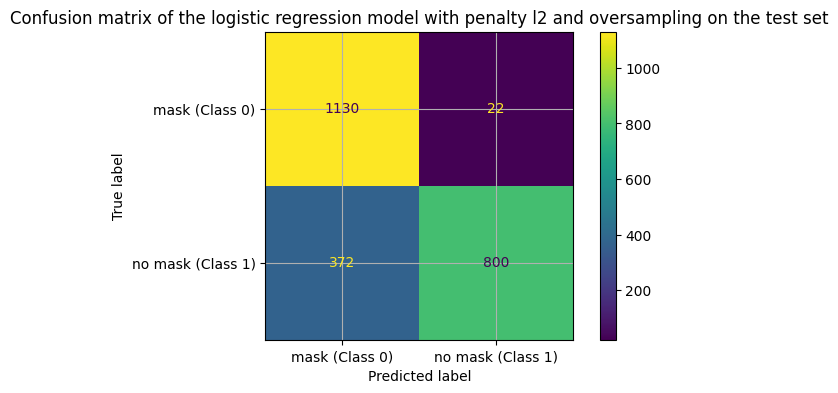


We observe that indeed the model classifies better the images with a mask (Class 0) than the images without a mask. This is consistent with everything that was discussed in this part previously.
However, we observe that the model is less good on the test set, which is logical because it's data it has never seen.
Thus the scores change from the previous evaluation on the validation set.add

As discussed in a previous question, the duplicates don't help the model to learn new information, but it can help give more visibility to the minority class.

We must not select a replacement model using the test set, because it is exactly used for that: to test how the model performs on unseen data. Thus it would make no sense to use it to select another model.

As stated previously, the limitations of the training set that we used is that the classes are highly unbalanced. Thus for the better model choice it would have been better to have a more diverse dataset with more images from class 1.


In [31]:
# TODO: answer Question 29, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
images_train, labels_train = load_file('train')
images_extra, labels_extra = load_file('extra')

X_full = np.vstack((image_features(images_train), image_features(images_extra)))
y_full = np.concatenate((labels_train, labels_extra))

X_full_os, y_full_os = oversample_minority_class(X_full, y_full, seed=SEED)

model_full = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=SEED, penalty='l2', C=best_C, solver='lbfgs')
) # C_best=100 taken from question 26

model_full.fit(X_full_os, y_full_os)

# evaluate on test set
final_metrics = evaluate(model_full)

# confusion matrix
images_test, labels_test = load_file('test')
X_test = image_features(images_test)

y_test_pred = model_full.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    labels_test, 
    y_test_pred, 
    display_labels=['mask (Class 0)', 'no mask (Class 1)']
)
plt.title('Confusion matrix of the logistic regression model with penalty l2 and oversampling on the test set')
plt.show()

display(Markdown(r"""
We observe that indeed the model classifies better the images with a mask (Class 0) than the images without a mask. This is consistent with everything that was discussed in this part previously.
However, we observe that the model is less good on the test set, which is logical because it's data it has never seen.
Thus the scores change from the previous evaluation on the validation set.add

As discussed in a previous question, the duplicates don't help the model to learn new information, but it can help give more visibility to the minority class.

We must not select a replacement model using the test set, because it is exactly used for that: to test how the model performs on unseen data. Thus it would make no sense to use it to select another model.

As stated previously, the limitations of the training set that we used is that the classes are highly unbalanced. Thus for the better model choice it would have been better to have a more diverse dataset with more images from class 1.
"""))


Before submission, restart the kernel and run your notebook in order. Check that
every required question has an explanation, every figure is labelled, and your
reported conclusions match your actual outputs. Include a short account of any
AI assistance and the checks you performed. Keep the final-test result as the
assessment of your frozen procedure rather than using it for another tuning cycle.

*Statement on AI use*

I have used AI, mainly to debug some parts of code and gain time on the code for some graphs. I have used it to help me optimize some parts of the code, which allowed me to cut down drastically the execution time for certain parts. 